# Models 

XGBoost port of `final_notebook_2models.ipynb`. Two independent models are fitted on the
same rows and the same feature set:

* **Model A** — one shot at the three classes, `faster` / `no change` / `slower`.
* **Model B** — binary, `slower` / `not slower`, with a routing-style probability cutoff
  selected inside the inner CV.

Model B is **not** a gate on Model A. The two are separate deliverables answering different
questions, they are not composable, and neither one's predictions can be reconstructed from
the other's. Model B exists because "is degradation slowed" is a decision-relevant question
on its own, and because a model relieved of the faster-versus-no-change job may draw the
slowdown boundary differently.

Everything to do with Morgan fingerprints and bitcodes has been removed.

## What changed from the HistGradientBoosting version

* The estimator is `XGBClassifier` with `tree_method="hist"` and `enable_categorical=True`.
  Categorical predictors keep pandas `category` dtype and are passed through as one column
  each — they are **not** one-hot expanded. `enable_categorical` must be set explicitly on
  XGBoost 3.2; it becomes the default in 3.3.
* `SEARCH_SPACE` is XGBoost's parameter set. `class_weight` survives as a pseudo-parameter:
  XGBoost has no such argument, so `fit_model` pops it and translates it into
  `sample_weight=compute_sample_weight("balanced", ...)`. Section 7.1's diagnostic therefore
  still reads the way it did.
* `fit_model` returns a `LabelledXGB` wrapper. XGBoost requires integer targets and calls the
  raw scores `predict(..., output_margin=True)`; the wrapper restores the string-label
  `classes_` / `predict` / `predict_proba` / `decision_function` interface that the rest of
  this notebook was written against. **Because of it, section 10's code carries over
  unchanged** — the only edits there are two stale comments, one of which referred to
  TreeSHAP's bitset handling.
* Feature selection and interaction construction now live in one editable cell, section 5.
* Model A reports a directional reversal rate alongside the existing metrics.


## Protocol invariants

* `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)`, grouped by `Study ID`.
* `SEEDS = range(5)`, `N_OUTER, N_INNER, N_DRAWS = 5, 4, 30`.
* **Model A stratifies on the three-class label; Model B stratifies on its own binary label.**
  The two runs therefore do not share folds. That is deliberate: each model splits the way its
  own task would. The cost is that A and B cannot be compared row by row, only at the level of
  the per-seed distributions.
* Model B's cutoff is chosen inside the inner CV alongside the hyperparameters and frozen
  before the outer test fold is touched. It is scored on Model B's own balanced accuracy.
* Both models search the full hyperparameter space, `class_weight` included. Model B therefore
  has two levers pointing the same way (the class weighting and the cutoff). The cutoff spread
  across the 25 folds in section 7.1 is the diagnostic: if it scatters across the whole grid,
  pin `class_weight` to `[None]` for B and rerun.

And the standing prohibitions:

* No recursive feature elimination with refits; no sweeping "best k" against outer performance.
* Nothing may be selected anywhere the outer test fold can influence it.
* SHAP is computed on the refit models over all rows (section 10), never on the folds, and it
  is read *after* the feature set is fixed — never used to choose it.


In [9]:
from __future__ import annotations

import json
import pickle
import time
from pathlib import Path

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.stats import loguniform, randint, uniform
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import ParameterSampler, StratifiedGroupKFold
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

import xgboost

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

## 1. Features

### 1.1 Constants

Unchanged from the HistGradientBoosting notebook apart from the label sets. `STAGE1_ORDER` is
gone; `BINARY_ORDER` takes its place and describes a different partition of the same three
classes.


In [10]:
SEEDS = list(range(5))
N_OUTER, N_INNER, N_DRAWS = 5, 4, 30

# v5: the six hydrophobicity descriptors that DERIVED replaces.
FAMILY = [
    "chemspider__LogP",
    "pesticide_logD55",
    "pesticide_logD74",
    "pesticide_logD_pH_sensitivity",
    "Hydrophobicity",
    "Mobility",
]

# v6: soil-pH-adjusted LogD.
DERIVED = "pesticide_logD_at_soil_pH"

# v7: Tier B additions.
TIER_B_EXTRA = ["Replicates", "soil_pH", "soil_OC", "amendment_carbon", "amendment_pH"]

ORDER = ["faster", "no change", "slower"]
BINARY_ORDER = ["not slower", "slower"]
POSITIVE = "slower"

# Anything named here is cast to pandas `category` dtype when it appears in the feature list,
# and XGBoost is told to treat it as categorical. Extend it if you add a categorical feature.
KNOWN_CATEGORICAL = {
    "pesticide_class",
    "pesticide_rdkit_cluster",
    "feedstock_group",
    "processing_group",
    "amendment_cluster_chemical",
    "soil_cluster",
    "soil_texture",
    "DT50 class",
}

METRICS = {
    "balanced_accuracy": balanced_accuracy_score,
    "accuracy": accuracy_score,
}


### 1.2 `add_soil_ph_logd` — copied verbatim from v6

`DERIVED = LogD5.5 + ((clip(soil_pH, 5.5, 7.4) - 5.5) / 1.9) * (LogD7.4 - LogD5.5)`

Soil pH is clipped to the two measurement anchors, so rows outside 5.5–7.4 are held at the
nearest anchor rather than extrapolated. Rows with missing `soil_pH` stay NaN, which is the
lower coverage recorded against V6 in the register. Linear interpolation is exploratory and
the real LogD–pH response can be nonlinear near the pKa; that is a property of the feature,
not of this notebook.


In [11]:
def add_soil_ph_logd(frame: pd.DataFrame) -> pd.DataFrame:
    """Linearly interpolate LogD5.5--LogD7.4 at clipped measured soil pH."""
    result = frame.copy()
    clipped_ph = result["soil_pH"].clip(lower=5.5, upper=7.4)
    fraction = (clipped_ph - 5.5) / (7.4 - 5.5)
    result[DERIVED] = (
        result["pesticide_logD55"]
        + fraction * (result["pesticide_logD74"] - result["pesticide_logD55"])
    )
    return result


def adjusted_logd_b_features(config: dict) -> list[str]:
    """The `adjusted_logD_B` feature set, from a loaded run config."""
    return [f for f in config["tiers"]["A"] if f not in FAMILY] + [DERIVED] + TIER_B_EXTRA


def load_run(baseline_run: Path) -> tuple[pd.DataFrame, dict]:
    """Load `model_df.pkl` + `config.json` from a run directory and add DERIVED."""
    with (baseline_run / "model_df.pkl").open("rb") as handle:
        frame = add_soil_ph_logd(pickle.load(handle)).reset_index(drop=True)
    config = json.loads((baseline_run / "config.json").read_text())
    return frame, config


def coverage_report(frame: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    """Missingness per feature -- DERIVED is the one that moves."""
    return (
        frame[features]
        .isna()
        .mean()
        .rename("fraction_missing")
        .sort_values(ascending=False)
        .to_frame()
        .query("fraction_missing > 0")
    )


## 2. Parameters

**Both paths are placeholders and must be edited.** They are relative, so they resolve against
the kernel's working directory, not the notebook's location.

`DROP` is a blunt safety net: anything named in it is stripped from the feature list no matter
what section 5 selects. With section 5 now holding an explicit feature list, `DROP` is mostly
redundant — keep it for columns that must never enter under any variant.


In [12]:
BASELINE_RUN = Path(".")        # directory holding model_df.pkl and config.json
OUTPUT_ROOT = Path("outputs")   # where this notebook writes its own results

DROP = ["Sterile/non-sterile", "Replicates"]

SEARCH_MODE = "joint"       # "joint" or "sequential" -- Model B's cutoff search, see 3.2

# Readable summary plots: one row per feature and the 15 most influential features.
# Increase MAX_DISPLAY for an appendix plot; categorical features are shown in grey.
EXPAND_LEVELS = False
MAX_DISPLAY = 15

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


## 3. Model core

### 3.1 Fitting

`SEARCH_SPACE` is XGBoost's, and **both** models use it.

`class_weight` is not an XGBoost parameter. It stays in the search space as a pseudo-parameter
because the balanced-versus-unweighted choice is a real lever and section 7.1's diagnostic
reads it; `fit_model` pops it out before constructing the estimator and turns `"balanced"` into
a `sample_weight` vector. Nothing else in the notebook needs to know.

`fit_model` returns a `LabelledXGB`. XGBoost's sklearn wrapper requires integer targets, so the
class labels are encoded on the way in and decoded on the way out. The wrapper exposes
`classes_`, `predict`, `predict_proba` and `decision_function` with string labels, which is what
`class_probability`, `contrast` and the SHAP wrapper in section 10 expect. `decision_function`
maps to `predict(..., output_margin=True)`: raw margin scores, shape `(n, 3)` for Model A and
`(n,)` for Model B — the same shapes `HistGradientBoostingClassifier.decision_function` gave.

`as_categorical` casts the declared categorical columns to pandas `category` dtype **once, on
the whole frame**, so every fold sees the same category set and the codes are stable. That
matters twice over here: XGBoost 3.1+ stores the training categories in the model and re-codes
at inference, and `numeric_view` in section 10 has to reproduce the model's own encoding.


In [13]:
SEARCH_SPACE = {
    "n_estimators": randint(80, 401),
    "max_depth": randint(2, 7),
    "learning_rate": loguniform(0.01, 0.2),
    "min_child_weight": loguniform(0.5, 20),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_lambda": loguniform(0.1, 30),
    "reg_alpha": loguniform(0.001, 3),
    "class_weight": [None, "balanced"],   # pseudo-parameter, see fit_model
}

# Cutoff on p(slower) for Model B. 0.5 is plain argmax.
CUTOFF_GRID = np.round(np.arange(0.10, 0.901, 0.01), 3)

# Categoricals with at most this many levels get one-hot splits inside XGBoost; above it,
# gradient-sorted optimal partitioning. Left at the library default.
MAX_CAT_TO_ONEHOT = 4


def as_categorical(frame: pd.DataFrame, categorical: list[str]) -> pd.DataFrame:
    """Cast declared categorical columns to `category` dtype, once, over all rows."""
    result = frame.copy()
    for column in categorical:
        if column in result.columns and not isinstance(result[column].dtype, pd.CategoricalDtype):
            result[column] = result[column].astype("category")
    return result


def numeric_view(X: pd.DataFrame) -> pd.DataFrame:
    """Integer-coded copy of X for SHAP, preserving NaN.

    With `enable_categorical=True` XGBoost consumes the `category` dtype directly and encodes
    each level by its position in `cat.categories`, so `.cat.codes` reproduces the model's own
    encoding. Missing values stay NaN rather than becoming -1, so the tree walk sees them as
    missing.
    """
    out = {}
    for name, column in X.items():
        if isinstance(column.dtype, pd.CategoricalDtype):
            codes = column.cat.codes.astype(float)
            out[name] = codes.where(codes >= 0, np.nan)
        elif pd.api.types.is_numeric_dtype(column):
            out[name] = column.astype(float)
        else:
            codes = pd.Series(pd.factorize(column)[0], index=X.index).astype(float)
            out[name] = codes.where(codes >= 0, np.nan)
    return pd.DataFrame(out, index=X.index)[list(X.columns)]


def label_order(y) -> list[str]:
    """Which label set this target uses. `not slower` exists only in the binary labelling."""
    return BINARY_ORDER if "not slower" in set(pd.Series(y).dropna().unique()) else ORDER


class LabelledXGB:
    """An XGBClassifier fitted on integer codes, wearing the string-label interface.

    HistGradientBoosting accepted string labels, exposed `classes_`, and had a
    `decision_function`. XGBoost requires integer targets and names the raw scores
    `predict(..., output_margin=True)`. Everything downstream of `fit_model` talks to this
    object, so `class_probability`, `contrast` and `make_wrapper` are unchanged.
    """

    def __init__(self, model: XGBClassifier, classes: list[str]):
        self.model = model
        self.classes_ = np.asarray(classes, dtype=object)

    def predict(self, X):
        return self.classes_[np.asarray(self.model.predict(X)).astype(int)]

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def decision_function(self, X):
        """Raw margin. (n, 3) for the three-class model, (n,) for the binary one."""
        return self.model.predict(X, output_margin=True)


def fit_model(params, X, y, seed, categorical=None):
    """Fit XGBoost on string labels. `categorical` is accepted and ignored: the `category`
    dtype on the columns already carries that information, and it keeps every call site
    identical to the HistGradientBoosting notebook."""
    settings = dict(params)
    weighting = settings.pop("class_weight", None)

    classes = label_order(y)
    codes = pd.Categorical(y, categories=classes).codes
    if (codes < 0).any():
        raise ValueError("target contains labels outside the expected set")

    weights = compute_sample_weight("balanced", codes) if weighting == "balanced" else None
    constraints = monotone_constraints(X) if len(classes) == 2 else {}
    model = XGBClassifier(
        objective="multi:softprob" if len(classes) > 2 else "binary:logistic",
        eval_metric="mlogloss" if len(classes) > 2 else "logloss",
        tree_method="hist",
        enable_categorical=True,          # required on 3.2; default from 3.3
        max_cat_to_onehot=MAX_CAT_TO_ONEHOT,
        random_state=seed,
        n_jobs=1,                         # the outer joblib loop owns the cores
        monotone_constraints = constraints,
        **settings,
    )
    model.fit(X, codes, sample_weight=weights)
    return LabelledXGB(model, classes)


def class_probability(model, X, label):
    return model.predict_proba(X)[:, list(model.classes_).index(label)]


def binary_labels(observed: pd.Series) -> pd.Series:
    """Three classes collapsed to slower / not slower."""
    return observed.where(observed.eq(POSITIVE), "not slower")


def reversal_mask(observed, predicted) -> np.ndarray:
    """Observed faster predicted slower, or observed slower predicted faster."""
    observed = pd.Series(observed).astype(object).reset_index(drop=True)
    predicted = pd.Series(predicted).astype(object).reset_index(drop=True)
    return (
        (observed.eq("faster") & predicted.eq("slower"))
        | (observed.eq("slower") & predicted.eq("faster"))
    ).to_numpy()


### 3.2 Inner searches

Unchanged in form from the HistGradientBoosting notebook — only what `fit_model` builds
underneath them is different.

**Model A**: 30 draws, each fitted on every inner fold, ranked by mean-across-folds balanced
accuracy.

**Model B** reuses the cutoff machinery, retargeted at `p(slower)`. Each draw is fitted once per
inner fold; every candidate cutoff is then scored on the resulting validation probabilities, so
sweeping the whole grid costs no extra fits. Per-fold scores are averaged across inner folds
rather than pooled.

* `mode="joint"` — score all 30 draws against all cutoffs and take the best pair.
* `mode="sequential"` — pick the draw at cutoff 0.5, then pick that draw's best cutoff.


In [14]:
def score_draw(params, X, y, splits, seed, categorical):
    return np.mean([
        balanced_accuracy_score(
            y.iloc[validation],
            fit_model(params, X.iloc[training], y.iloc[training], seed, categorical).predict(
                X.iloc[validation]
            ),
        )
        for training, validation in splits
    ])


def inner_search(X, y, groups, seed, categorical):
    """Model A's search. Nothing here sees the outer test fold."""
    splitter = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=seed)
    splits = list(splitter.split(X, y, groups))
    draws = list(ParameterSampler(SEARCH_SPACE, n_iter=N_DRAWS, random_state=seed))
    scores = Parallel(n_jobs=-1)(
        delayed(score_draw)(params, X, y, splits, seed, categorical) for params in draws
    )
    best = int(np.argmax(scores))
    return draws[best], float(scores[best])


def cutoff_scores(params, X, y, splits, seed, categorical, grid):
    """Mean-across-inner-folds balanced accuracy for every cutoff in `grid`."""
    per_fold = []
    for training, validation in splits:
        model = fit_model(params, X.iloc[training], y.iloc[training], seed, categorical)
        p = class_probability(model, X.iloc[validation], POSITIVE)
        truth = y.iloc[validation].to_numpy()
        per_fold.append([
            balanced_accuracy_score(truth, np.where(p >= cutoff, POSITIVE, "not slower"))
            for cutoff in grid
        ])
    return np.asarray(per_fold, dtype=float).mean(axis=0)


def inner_search_binary(X, y, groups, seed, categorical, grid=CUTOFF_GRID, mode="joint"):
    """Model B's search. Returns (params, cutoff, inner_score)."""
    splitter = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=seed)
    splits = list(splitter.split(X, y, groups))
    draws = list(ParameterSampler(SEARCH_SPACE, n_iter=N_DRAWS, random_state=seed))
    scored = np.vstack(Parallel(n_jobs=-1)(
        delayed(cutoff_scores)(params, X, y, splits, seed, categorical, grid)
        for params in draws
    ))
    if mode == "joint":
        draw_index, cutoff_index = np.unravel_index(int(np.argmax(scored)), scored.shape)
    elif mode == "sequential":
        default = int(np.argmin(np.abs(np.asarray(grid) - 0.5)))
        draw_index = int(np.argmax(scored[:, default]))
        cutoff_index = int(np.argmax(scored[draw_index]))
    else:
        raise ValueError(f"unknown mode: {mode}")
    return (
        draws[int(draw_index)],
        float(grid[int(cutoff_index)]),
        float(scored[int(draw_index), int(cutoff_index)]),
    )


### 3.3 Runners

One runner per model. Each returns `(metrics, oof, folds, fits)` and each keeps its fitted
per-fold models.

Note the two `outer.split` calls stratify on different labels, which is what makes the folds
differ between the two runs.

Model A's metric row carries balanced accuracy, accuracy, macro F1, the three class recalls and
the directional reversal rate — `faster` predicted `slower` or `slower` predicted `faster`, as a
fraction of all rows. Reversals are undefined for Model B, which has merged `faster` and
`no change` into a single class, so its row keeps the threshold-free ranking metrics instead.


In [15]:
def _oof_frame(frame, groups, extra: dict) -> pd.DataFrame:
    base = {"Study ID": groups}
    if "analysis_row_id" in frame.columns:
        base["analysis_row_id"] = frame["analysis_row_id"]
    return pd.DataFrame({**base, **extra})


def run_one_multiclass(frame, features, seed, categorical, variant="three_class", keep_models=True):
    """Model A: one shot at the three classes."""
    X = frame[features]
    observed = frame["response_class"]
    groups = frame["Study ID"]
    outer = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)

    predicted = pd.Series(pd.NA, index=frame.index, dtype="object")
    proba = pd.DataFrame(np.nan, index=frame.index, columns=ORDER)
    fold_ids = pd.Series(np.nan, index=frame.index)
    fold_rows, fits = [], []

    for fold, (training, test) in enumerate(outer.split(X, observed, groups)):
        params, inner = inner_search(
            X.iloc[training], observed.iloc[training], groups.iloc[training], seed, categorical
        )
        model = fit_model(params, X.iloc[training], observed.iloc[training], seed, categorical)
        columns = [list(model.classes_).index(label) for label in ORDER]

        predicted.iloc[test] = model.predict(X.iloc[test])
        proba.iloc[test] = model.predict_proba(X.iloc[test])[:, columns]
        fold_ids.iloc[test] = fold

        fold_rows.append({
            "variant": variant, "seed": seed, "fold": fold,
            "n_test": len(test), "studies_test": groups.iloc[test].nunique(),
            "inner_bacc": inner,
            "outer_bacc": balanced_accuracy_score(observed.iloc[test], predicted.iloc[test]),
            **{f"hp_{name}": value for name, value in params.items()},
        })
        if keep_models:
            fits.append({"variant": variant, "seed": seed, "fold": fold,
                         "training": training, "test": test, "model": model})

    recalls = recall_score(observed, predicted, labels=ORDER, average=None)
    reversals = reversal_mask(observed, predicted)
    metrics = {
        "variant": variant, "seed": seed,
        "bal_acc": balanced_accuracy_score(observed, predicted),
        "accuracy": accuracy_score(observed, predicted),
        "macro_f1": f1_score(observed, predicted, average="macro"),
        **{f"recall_{label.replace(' ', '_')}": value for label, value in zip(ORDER, recalls)},
        "reversal_rate": float(reversals.mean()),
        "n_reversals": int(reversals.sum()),
    }
    oof = _oof_frame(frame, groups, {
        "variant": variant, "seed": seed, "fold": fold_ids,
        "observed": observed, "predicted": predicted,
        "correct": observed.eq(predicted),
        "directional_reversal": reversals,
        **{f"p_{label.replace(' ', '_')}": proba[label] for label in ORDER},
    })
    return metrics, oof, pd.DataFrame(fold_rows), fits


def run_one_binary(frame, features, seed, categorical, variant="slower_or_not",
                   cutoff_grid=CUTOFF_GRID, mode="joint", keep_models=True):
    """Model B: slower versus not slower, with an inner-selected cutoff on p(slower)."""
    X = frame[features]
    observed = binary_labels(frame["response_class"])
    groups = frame["Study ID"]
    outer = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)

    predicted = pd.Series(pd.NA, index=frame.index, dtype="object")
    p_slower = pd.Series(np.nan, index=frame.index)
    fold_cutoff = pd.Series(np.nan, index=frame.index)
    fold_ids = pd.Series(np.nan, index=frame.index)
    fold_rows, fits = [], []

    for fold, (training, test) in enumerate(outer.split(X, observed, groups)):
        params, cutoff, inner = inner_search_binary(
            X.iloc[training], observed.iloc[training], groups.iloc[training],
            seed, categorical, cutoff_grid, mode,
        )
        model = fit_model(params, X.iloc[training], observed.iloc[training], seed, categorical)
        p = class_probability(model, X.iloc[test], POSITIVE)

        p_slower.iloc[test] = p
        predicted.iloc[test] = np.where(p >= cutoff, POSITIVE, "not slower")
        fold_cutoff.iloc[test] = cutoff
        fold_ids.iloc[test] = fold

        fold_rows.append({
            "variant": variant, "seed": seed, "fold": fold,
            "n_test": len(test), "studies_test": groups.iloc[test].nunique(),
            "cutoff": cutoff, "inner_bacc": inner,
            "outer_bacc": balanced_accuracy_score(observed.iloc[test], predicted.iloc[test]),
            **{f"hp_{name}": value for name, value in params.items()},
        })
        if keep_models:
            fits.append({"variant": variant, "seed": seed, "fold": fold, "cutoff": cutoff,
                         "training": training, "test": test, "model": model})

    truth = observed.eq(POSITIVE).astype(int)
    cutoffs = np.array([row["cutoff"] for row in fold_rows], dtype=float)
    metrics = {
        "variant": variant, "seed": seed,
        "bal_acc": balanced_accuracy_score(observed, predicted),
        "accuracy": accuracy_score(observed, predicted),
        "macro_f1": f1_score(observed, predicted, average="macro"),
        "recall_slower": recall_score(observed, predicted, pos_label=POSITIVE),
        "recall_not_slower": recall_score(observed, predicted, pos_label="not slower"),
        "precision_slower": precision_score(observed, predicted, pos_label=POSITIVE,
                                            zero_division=0),
        "f1_slower": f1_score(observed, predicted, pos_label=POSITIVE),
        # Threshold-free, so these describe the ranking independently of the tuned cutoff.
        "roc_auc": roc_auc_score(truth, p_slower),
        "pr_auc": average_precision_score(truth, p_slower),
        "predicted_slower_n": int(predicted.eq(POSITIVE).sum()),
        "cutoff_mean": float(cutoffs.mean()),
        "cutoff_min": float(cutoffs.min()),
        "cutoff_max": float(cutoffs.max()),
    }
    oof = _oof_frame(frame, groups, {
        "variant": variant, "seed": seed, "fold": fold_ids,
        "observed": observed, "predicted": predicted,
        "correct": observed.eq(predicted),
        "p_slower": p_slower, "cutoff": fold_cutoff,
    })
    return metrics, oof, pd.DataFrame(fold_rows), fits


def run_variant(frame, features, categorical, runner, variant, seeds=SEEDS,
                verbose=True, **kwargs):
    metric_rows, oof_parts, fold_parts, all_fits = [], [], [], []
    for seed in seeds:
        metrics, oof, folds, fits = runner(
            frame, features, seed, categorical, variant=variant, **kwargs
        )
        metric_rows.append(metrics)
        oof_parts.append(oof)
        fold_parts.append(folds)
        all_fits.extend(fits)
        if verbose:
            tail = (f" cutoff {metrics['cutoff_min']:.2f}-{metrics['cutoff_max']:.2f}"
                    if "cutoff_min" in metrics else
                    f" rev={metrics['reversal_rate']:.3f}")
            print(
                f"{variant:<16} seed {seed}: bacc={metrics['bal_acc']:.3f} "
                f"acc={metrics['accuracy']:.3f} F1={metrics['macro_f1']:.3f}{tail}",
                flush=True,
            )
    return (
        pd.DataFrame(metric_rows),
        pd.concat(oof_parts, ignore_index=True),
        pd.concat(fold_parts, ignore_index=True),
        all_fits,
    )


## 4. Load


In [ ]:
# --- execution cell ---
frame, config = load_run(BASELINE_RUN)

ALL_TIER_A = [f for f in config["tiers"]["A"] if f not in DROP]
ADJUSTED_LOGD_B = [f for f in adjusted_logd_b_features(config) if f not in DROP]

# print(f"{len(frame)} rows, {frame['Study ID'].nunique()} studies, {frame.shape[1]} columns")
# print()
# print("tier A, as loaded:")
# print("   ", ", ".join(ALL_TIER_A))
# print()
# print("adjusted_logD_B (the old default feature set):")
# print("   ", ", ".join(ADJUSTED_LOGD_B))

display(frame["response_class"].value_counts().rename("rows").to_frame())
display(binary_labels(frame["response_class"]).value_counts().rename("rows").to_frame())


450 rows, 67 studies, 55 columns

tier A, as loaded:
    pesticide_class, pesticide_rdkit_cluster, pesticide_MW, pesticide_logD74, pesticide_logD55, chemspider__LogP, pesticide_logD_pH_sensitivity, Hydrophobicity, Mobility, DT50 class, feedstock_group, processing_group, amendment_application_rate_g_kg, soil_cluster, soil_texture, soil_clay, soil_silt, temperature_mean_c, log_DT50_control, log1p_pesticide_concentration

adjusted_logD_B (the old default feature set):
    pesticide_class, pesticide_rdkit_cluster, pesticide_MW, DT50 class, feedstock_group, processing_group, amendment_application_rate_g_kg, soil_cluster, soil_texture, soil_clay, soil_silt, temperature_mean_c, log_DT50_control, log1p_pesticide_concentration, pesticide_logD_at_soil_pH, soil_pH, soil_OC, amendment_carbon, amendment_pH


,rows
response_class,
faster,198
slower,146
no change,106


,rows
response_class,
not slower,304
slower,146


In [ ]:
# frame.columns

Index(['response_class', 'ln_DT50_ratio', 'DT50_ratio', 'DT50_control', 'analysis_row_id', 'Study ID', 'Experiment ID', 'Soil ID', 'Amendment ID',
       'Pesticide ID', 'matched_control_row_id', 'Pesticide name', 'consolidated_label', 'bitcode', 'pesticide_class', 'pesticide_rdkit_cluster',
       'pesticide_logD74', 'pesticide_logD55', 'chemspider__LogP', 'pesticide_logD_pH_sensitivity', 'pesticide_MW', 'Hydrophobicity', 'Mobility', 'DT50 class',
       'feedstock_group', 'processing_group', 'amendment_cluster_chemical', 'amendment_pH', 'amendment_N', 'amendment_carbon',
       'amendment_application_rate_g_kg', 'soil_pH', 'soil_OC', 'soil_clay', 'soil_silt', 'soil_texture', 'soil_cluster', 'temperature_mean_c',
       'Sterile/non-sterile', 'Replicates', 'log_DT50_control', 'amendment_soil_pH_difference', 'log1p_pesticide_concentration', 'carbon_value_valid',
       'nitrogen_value_valid', 'pesticide_concentration_conversion_status', 'control_matching_rule', 'soil_OC_source', 'amend

### 4.1 Bringing in a new feature

Placeholder. If a new predictor arrives from outside `model_df.pkl` — a new descriptor table, a
recomputed property, an external join — attach it **here**, before section 5, so that section 5
can select it and every downstream section picks it up without further edits.

Two rules for anything added here:

* It must be a **row-level** property, joined on a key already in `frame`. Do not join on
  anything derived from `response_class` and do not aggregate over rows that share a fold.
* It must be computable for a new, unseen row at prediction time. A column that encodes
  something only knowable after the experiment finished is leakage, however well it scores.

Nothing in this cell runs by default.


In [ ]:
# --- execution cell: new-feature import ---
#
# Pattern A -- join a table keyed on something already in `frame`
#
#     extra = pd.read_csv("data/new_pesticide_descriptors.csv")
#     before = len(frame)
#     frame = frame.merge(
#         extra[["Pesticide ID", "new_descriptor"]],
#         on="Pesticide ID",
#         how="left",
#         validate="many_to_one",     # fails loudly if `extra` has duplicate keys
#     )
#     assert len(frame) == before, "merge changed the row count"
#
# Pattern B -- derive a column from what is already there
#
#     frame["amendment_c_to_n"] = frame["amendment_carbon"] / frame["amendment_N"]
#
# Then, whichever pattern: report coverage, and add the name to KNOWN_CATEGORICAL in
# section 1.1 if it is categorical.
#
#     print(frame["new_descriptor"].isna().mean().round(3), "missing")
#     display(frame["new_descriptor"].describe())
#
# Finally add the name to SELECTED_FEATURES in section 5 -- nothing enters a model until
# it is listed there.
#
# Sheets in extraction_main carry three rows of preamble, so header=3, and their columns
# are spaced rather than underscored: "Amendment ID", not "Amendment_ID".

from rdkit import Chem
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")

BIOWIN_XLSX = Path("EpiSuite_BioWin_results_clean.xlsx")
EXTRACTION_XLSX = Path("extraction_main.xlsx")
BIOWIN_COLUMN = "biowin4_primary"
BIOCHAR_COLUMN = "is_biochar"


def canonical_smiles(smiles):
    """RDKit canonical form, or None if the string will not parse."""
    if not isinstance(smiles, str) or not smiles.strip():
        return None
    molecule = Chem.MolFromSmiles(smiles.strip())
    return Chem.MolToSmiles(molecule) if molecule is not None else None


# ---------------------------------------------------------------------------
# BioWin4 -- primary biodegradation timeframe, joined via SMILES
# ---------------------------------------------------------------------------

# 1. Pesticide ID -> SMILES. The sheet's real header is on the fourth row.
pesticides = (
    pd.read_excel(EXTRACTION_XLSX, sheet_name="pesticide_properties", header=3)
    .dropna(how="all")
    .loc[:, ["Pesticide ID", "Pesticide name", "SMILES code"]]
    .dropna(subset=["Pesticide ID"])
)
if pesticides["Pesticide ID"].duplicated().any():
    raise ValueError("Pesticide ID is not unique in pesticide_properties")
pesticides["smiles_canonical"] = pesticides["SMILES code"].map(canonical_smiles)

# 2. SMILES -> BioWin4. BioWin3 is ultimate biodegradation and is deliberately not carried:
#    DT50 tracks disappearance of the parent, which is primary degradation, and the two
#    columns correlate at r = 0.82.
biowin = pd.read_excel(BIOWIN_XLSX).rename(
    columns={"BioWin4 (Primary Biodegradation Timeframe)": BIOWIN_COLUMN}
)
biowin["smiles_canonical"] = biowin["SMILES"].map(canonical_smiles)
biowin = (
    biowin.dropna(subset=["smiles_canonical", BIOWIN_COLUMN])
    .drop_duplicates("smiles_canonical")
    .loc[:, ["smiles_canonical", BIOWIN_COLUMN]]
)

# 3. Chain into a Pesticide ID lookup.
lookup = pesticides.merge(
    biowin, on="smiles_canonical", how="left", validate="many_to_one"
).loc[:, ["Pesticide ID", BIOWIN_COLUMN]]

# 4. Attach to frame. Idempotent, so the cell can be re-run.
frame = frame.drop(columns=[BIOWIN_COLUMN], errors="ignore")
before = len(frame)
frame = frame.merge(lookup, on="Pesticide ID", how="left", validate="many_to_one")
if len(frame) != before:
    raise ValueError(f"merge changed the row count: {before} -> {len(frame)}")


# ---------------------------------------------------------------------------
# Biochar Y/N -- derived from Amendment type, joined on Amendment ID
# ---------------------------------------------------------------------------

# 1. Amendment ID -> Amendment type.
amendments = (
    pd.read_excel(EXTRACTION_XLSX, sheet_name="amendment_properties", header=3)
    .dropna(how="all")
    .loc[:, ["Amendment ID", "Amendment type"]]
    .dropna(subset=["Amendment ID"])
)
if amendments["Amendment ID"].duplicated().any():
    raise ValueError("Amendment ID is not unique in amendment_properties")

# 2. 1.0 biochar, 0.0 some other amendment, NaN where the type is blank. NaN stays NaN:
#    "not recorded" is not the same claim as "not biochar", and XGBoost routes missing
#    down its own learned branch.
types = amendments["Amendment type"].astype("string").str.strip()
amendments[BIOCHAR_COLUMN] = types.str.casefold().eq("biochar").astype(float).where(types.notna())
lookup_biochar = amendments.loc[:, ["Amendment ID", BIOCHAR_COLUMN]]

# 3. Attach to frame. Idempotent, so the cell can be re-run.
frame = frame.drop(columns=[BIOCHAR_COLUMN], errors="ignore")
before = len(frame)
frame = frame.merge(lookup_biochar, on="Amendment ID", how="left", validate="many_to_one")
if len(frame) != before:
    raise ValueError(f"merge changed the row count: {before} -> {len(frame)}")


449 of 450 rows (99.8%) carry a biochar flag
29.6% of those are biochar


/home/jber/miniconda3/envs/repo_soilAI/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


,amendments
Amendment type,
<NA>,109
Biochar,104
Green waste,60
Compost,56
Manure,28
Straw,14
Vermicompost,10
Composite amendment,8
Sludge,7


## 5. Feature selection and interactions

**This is the only cell that decides what the two models see.** Both models always use the same
list.

`SELECTED_FEATURES` is set to the consensus eight. Comment a line out to drop a predictor;
uncomment or append to add one. The candidates block below the fold lists what is available in
the loaded frame, including everything the interaction screen touched.

`INTERACTIONS` builds pairwise products. Each entry is `"name": ("left", "right")` and produces
`left * right` as a new column, which is then added to the feature list. The four listed
commented-out are the ones tested in the interaction experiment; `silt × amendment carbon` is
the one that survived its confirmatory run.

Two things worth knowing before you reach for these. A product of two columns is NaN wherever
either input is NaN, so an interaction is at best as well-covered as its worse-covered parent —
check the coverage table this cell prints. And a gradient-boosted tree can already represent
interactions by splitting on one feature beneath the other; an explicit product helps mainly
when the effect is smooth and multiplicative and the trees are shallow. It is a hypothesis to
test against out-of-fold performance, not a free improvement.


In [ ]:
CONSENSUS_8 = [
    "soil_silt",
    "soil_pH",
    "feedstock_group",
    "amendment_pH",
    "amendment_carbon",
    "amendment_application_rate_g_kg",
    "log1p_pesticide_concentration",
    "pesticide_logD_at_soil_pH",
]

SELECTED_FEATURES = [
    "soil_silt",
    "soil_pH",
    "feedstock_group",
    "amendment_pH",
    "amendment_carbon",
    "amendment_application_rate_g_kg",
    "log1p_pesticide_concentration",
    "pesticide_logD_at_soil_pH", 
    "biowin4_primary", "is_biochar",

    # ---- available, currently out; uncomment to include ----
    # soil
    # "soil_OC",
    # "soil_clay",
    # "soil_texture",              # categorical
    # "soil_cluster",              # categorical
    # amendment / organic amendment context
    # "amendment_N",
    # "processing_group",          # categorical
    # "amendment_cluster_chemical",  # categorical
    # pesticide
    # "pesticide_MW",
    # "pesticide_class",           # categorical
    # "pesticide_rdkit_cluster",   # categorical
    # experimental context
    # "temperature_mean_c",
    # "log_DT50_control",
]

# "name": (left, right) -> frame["name"] = frame[left] * frame[right]
# ONLY WORKS ON CONTINUOUS FEATURES (aka most of them, except for the clusters)
# You do not need to add the interaction name to SELECTED_FEATURES
INTERACTIONS = {
    # "int_silt_x_amendment_carbon": ("soil_silt", "amendment_carbon"),
    # "int_silt_x_amendment_pH": ("soil_silt", "amendment_pH"),
    # "int_soil_OC_x_amendment_carbon": ("soil_OC", "amendment_carbon"),
    # "int_pesticide_concentration_x_amendment_carbon": ("log1p_pesticide_concentration", "amendment_carbon"),
}

#MONOTONICITY SELECTOR
# "feature": +1 -> the fitted score never decreases as the feature increases
#            -1 -> it never increases
# Applies to Model B (log-odds of `slower`) and Model C (the ordinal latent score). Both are
# coded so that higher means slower, so the sign means the same thing in both. Model A is
# multiclass and is left unconstrained because the function cannot accept the monotonicity argument. 
#
# Categorical features cannot be constrained.

MONOTONE = {
     "amendment_carbon": +1,
    # "biowin4_primary": -1,
}


def monotone_constraints(X: pd.DataFrame, specification: dict = None) -> dict:
    """Constraint dict for the columns of `X`, or an empty dict if nothing is constrained."""
    specification = MONOTONE if specification is None else specification
    if not specification:
        return {}

    unknown = [f for f in specification if f not in X.columns]
    if unknown:
        raise KeyError(f"constrained but not in the feature matrix: {unknown}")
    for name, sign in specification.items():
        if sign not in (-1, 0, 1):
            raise ValueError(f"{name}: constraint must be -1, 0 or +1, got {sign!r}")
        if isinstance(X[name].dtype, pd.CategoricalDtype) and sign != 0:
            raise TypeError(
                f"{name} is categorical. Its level order is arbitrary, so a monotone "
                f"constraint on it is not meaningful."
            )
    return {name: int(sign) for name, sign in specification.items() if sign != 0}
def add_interactions(frame: pd.DataFrame, specification: dict) -> pd.DataFrame:
    """Add one multiplicative column per entry. Non-numeric parents are rejected outright."""
    result = frame.copy()
    for name, parents in specification.items():
        left, right = parents
        missing = [c for c in (left, right) if c not in result.columns]
        if missing:
            raise KeyError(f"{name}: {missing} not in the frame")
        for parent in (left, right):
            if not pd.api.types.is_numeric_dtype(result[parent]):
                raise TypeError(
                    f"{name}: {parent} is not numeric. Products of categoricals are not "
                    f"meaningful -- let the trees interact them instead."
                )
        result[name] = result[left] * result[right]
    return result


def interaction_coverage(frame: pd.DataFrame, specification: dict) -> pd.DataFrame:
    rows = []
    for name, (left, right) in specification.items():
        rows.append({
            "interaction": name,
            "missing_left": frame[left].isna().mean(),
            "missing_right": frame[right].isna().mean(),
            "missing_product": frame[name].isna().mean(),
        })
    return pd.DataFrame(rows)


In [20]:
# --- execution cell ---
frame = add_interactions(frame, INTERACTIONS)

features = [f for f in SELECTED_FEATURES + list(INTERACTIONS) if f not in DROP]

unknown = [f for f in features if f not in frame.columns]
if unknown:
    raise KeyError(f"selected but not in the frame: {unknown}")
if len(features) != len(set(features)):
    raise ValueError("duplicate entries in the feature list")

categorical = [f for f in features if f in KNOWN_CATEGORICAL]
continuous = [f for f in features if f not in categorical]
frame = as_categorical(frame, categorical)

print(f"{len(frame)} rows, {frame['Study ID'].nunique()} studies, {len(features)} features "
      f"({len(continuous)} continuous, {len(categorical)} categorical)")
print("selection matches the consensus eight:", set(features) == set(CONSENSUS_8))
print("dropped:", DROP)
print("categorical:", categorical)
if INTERACTIONS:
    print("interactions:", list(INTERACTIONS))

if categorical:
    display(pd.Series(
        {c: frame[c].cat.categories.size for c in categorical}, name="levels"
    ).sort_values(ascending=False).to_frame())
display(coverage_report(frame, features))
if INTERACTIONS:
    display(interaction_coverage(frame, INTERACTIONS).round(3))


450 rows, 67 studies, 10 features (9 continuous, 1 categorical)
selection matches the consensus eight: False
dropped: ['Sterile/non-sterile', 'Replicates']
categorical: ['feedstock_group']


,levels
feedstock_group,4


,fraction_missing
amendment_pH,0.275556
amendment_carbon,0.191111
pesticide_logD_at_soil_pH,0.142222
soil_pH,0.142222
log1p_pesticide_concentration,0.075556
amendment_application_rate_g_kg,0.068889
soil_silt,0.044444
biowin4_primary,0.013333
is_biochar,0.002222


## 6. Model A — three classes, one shot


In [21]:
# --- execution cell ---
started = time.time()
metrics_a, oof_a, folds_a, fits_a = run_variant(
    frame, features, categorical, run_one_multiclass, "three_class",
)
print(f"elapsed: {(time.time() - started) / 60:.1f} min")
display(metrics_a.drop(columns="variant").round(4))
display(metrics_a.drop(columns=["variant", "seed"]).agg(["mean", "std"]).round(4))


three_class      seed 0: bacc=0.440 acc=0.453 F1=0.436 rev=0.242
three_class      seed 1: bacc=0.497 acc=0.511 F1=0.493 rev=0.171
three_class      seed 2: bacc=0.514 acc=0.529 F1=0.511 rev=0.173
three_class      seed 3: bacc=0.516 acc=0.540 F1=0.512 rev=0.171
three_class      seed 4: bacc=0.474 acc=0.493 F1=0.470 rev=0.180
elapsed: 1.8 min


,seed,bal_acc,accuracy,macro_f1,recall_faster,recall_no_change,recall_slower,reversal_rate,n_reversals
0,0,0.4402,0.4533,0.4357,0.4545,0.3113,0.5548,0.2422,109
1,1,0.4966,0.5111,0.4931,0.5303,0.3774,0.5822,0.1711,77
2,2,0.5145,0.5289,0.5112,0.5556,0.4057,0.5822,0.1733,78
3,3,0.5160,0.5400,0.5122,0.5808,0.3302,0.6370,0.1711,77
4,4,0.4735,0.4933,0.4696,0.5202,0.3113,0.5890,0.1800,81


,bal_acc,accuracy,macro_f1,recall_faster,recall_no_change,recall_slower,reversal_rate,n_reversals
mean,0.4882,0.5053,0.4844,0.5283,0.3472,0.5890,0.1876,84.4000
std,0.0318,0.0341,0.0323,0.0475,0.0424,0.0299,0.0308,13.8492


## 7. Model B — slower or not


In [22]:
# --- execution cell ---
started = time.time()
metrics_b, oof_b, folds_b, fits_b = run_variant(
    frame, features, categorical, run_one_binary, "slower_or_not", mode=SEARCH_MODE,
)
print(f"elapsed: {(time.time() - started) / 60:.1f} min")
display(metrics_b.drop(columns="variant").round(4))
display(metrics_b.drop(columns=["variant", "seed"]).agg(["mean", "std"]).round(4))


slower_or_not    seed 0: bacc=0.710 acc=0.702 F1=0.686 cutoff 0.34-0.51
slower_or_not    seed 1: bacc=0.668 acc=0.611 F1=0.609 cutoff 0.10-0.36
slower_or_not    seed 2: bacc=0.654 acc=0.658 F1=0.637 cutoff 0.24-0.62
slower_or_not    seed 3: bacc=0.692 acc=0.702 F1=0.679 cutoff 0.31-0.55
slower_or_not    seed 4: bacc=0.652 acc=0.662 F1=0.638 cutoff 0.24-0.56
elapsed: 1.4 min


,seed,bal_acc,accuracy,macro_f1,recall_slower,recall_not_slower,precision_slower,f1_slower,roc_auc,pr_auc,predicted_slower_n,cutoff_mean,cutoff_min,cutoff_max
0,0,0.7102,0.7022,0.6861,0.7329,0.6875,0.5297,0.6149,0.7683,0.5654,202,0.436,0.34,0.51
1,1,0.6677,0.6111,0.6090,0.8288,0.5066,0.4465,0.5803,0.6576,0.4242,271,0.262,0.10,0.36
2,2,0.6542,0.6578,0.6369,0.6438,0.6645,0.4796,0.5497,0.7252,0.5090,196,0.374,0.24,0.62
3,3,0.6924,0.7022,0.6786,0.6644,0.7204,0.5330,0.5915,0.7158,0.4826,182,0.452,0.31,0.55
4,4,0.6521,0.6622,0.6382,0.6233,0.6809,0.4840,0.5449,0.7324,0.5207,188,0.402,0.24,0.56


,bal_acc,accuracy,macro_f1,recall_slower,recall_not_slower,precision_slower,f1_slower,roc_auc,pr_auc,predicted_slower_n,cutoff_mean,cutoff_min,cutoff_max
mean,0.6753,0.6671,0.6497,0.6986,0.6520,0.4946,0.5763,0.7199,0.5004,207.8000,0.3852,0.2460,0.5200
std,0.0253,0.0378,0.0321,0.0836,0.0838,0.0366,0.0293,0.0401,0.0520,36.1414,0.0752,0.0926,0.0977


### 7.1 Cutoff stability

25 cutoffs, 5 folds x 5 seeds. Model B searches `class_weight` and the cutoff at the same time,
and the two are partly redundant. If the selected cutoffs scatter across the grid, the inner CV
is not identifying a stable operating point, and the fix is to pin `class_weight` to `[None]` in
`SEARCH_SPACE` for B and rerun section 7.


In [23]:
# --- execution cell ---
cutoffs = folds_b["cutoff"]
print(f"cutoff: mean {cutoffs.mean():.3f}, sd {cutoffs.std():.3f}, "
      f"range {cutoffs.min():.2f}-{cutoffs.max():.2f}, n={len(cutoffs)}")
display(folds_b.pivot_table(index="seed", columns="fold", values="cutoff"))
display(folds_b["hp_class_weight"].astype(str).value_counts().rename("folds").to_frame())


cutoff: mean 0.385, sd 0.128, range 0.10-0.62, n=25


fold,0,1,2,3,4
seed,,,,,
0,0.51,0.46,0.38,0.49,0.34
1,0.35,0.24,0.36,0.26,0.10
2,0.37,0.62,0.24,0.30,0.34
3,0.51,0.31,0.55,0.39,0.50
4,0.56,0.54,0.26,0.24,0.41


,folds
hp_class_weight,
balanced,12


## 8. Confusion matrices

Both matrices are pooled over all 25 outer folds, so every row of the dataset appears five
times, once per seed. These are out-of-fold predictions throughout — the refit models in
section 9 have no error estimate of their own and must never be used here.

Cells show raw counts with the row-normalised share underneath. Rows are true classes, so the
diagonal shares are recalls. In panel a the two off-diagonal corners are the directional
reversals summarised in `metrics_a`.


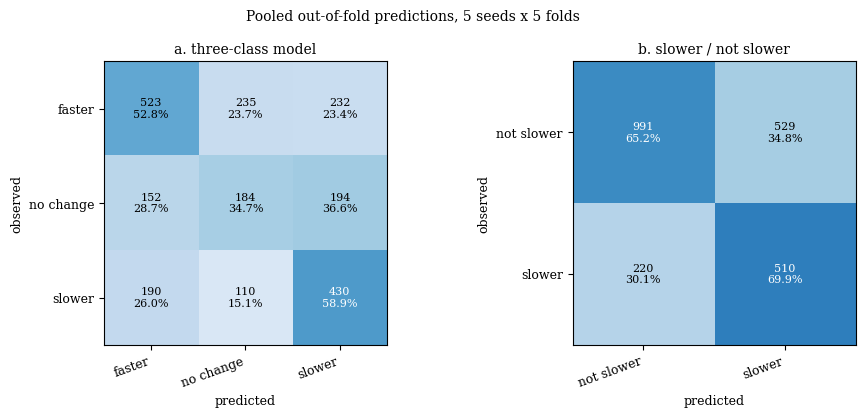

,faster,no change,slower
faster,523,235,232
no change,152,184,194
slower,190,110,430


,not slower,slower
not slower,991,529
slower,220,510


directional reversals: 422 of 2,250 pooled out-of-fold rows (18.8%)


In [24]:
# --- execution cell ---
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9})


def confusion_panel(axis, observed, predicted, labels, title):
    counts = confusion_matrix(observed, predicted, labels=labels)
    shares = counts / counts.sum(axis=1, keepdims=True)
    axis.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            axis.text(j, i, f"{counts[i, j]:,}\n{shares[i, j]:.1%}",
                      ha="center", va="center", fontsize=8,
                      color="white" if shares[i, j] > 0.55 else "black")
    axis.set_xticks(range(len(labels)), labels, rotation=20, ha="right")
    axis.set_yticks(range(len(labels)), labels)
    axis.set_xlabel("predicted")
    axis.set_ylabel("observed")
    axis.set_title(title, fontsize=10)
    return counts


figure, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), width_ratios=[3, 2])
counts_a = confusion_panel(axes[0], oof_a["observed"], oof_a["predicted"], ORDER,
                           "a. three-class model")
counts_b = confusion_panel(axes[1], oof_b["observed"], oof_b["predicted"], BINARY_ORDER,
                           "b. slower / not slower")
figure.suptitle("Pooled out-of-fold predictions, 5 seeds x 5 folds", fontsize=10)
figure.tight_layout()
figure.savefig(OUTPUT_ROOT / "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

display(pd.DataFrame(counts_a, index=ORDER, columns=ORDER))
display(pd.DataFrame(counts_b, index=BINARY_ORDER, columns=BINARY_ORDER))

print(f"directional reversals: {oof_a['directional_reversal'].sum():,} of {len(oof_a):,} "
      f"pooled out-of-fold rows ({oof_a['directional_reversal'].mean():.1%})")


## 9. Refit the deliverable models

The nested CV's job is the estimate above; the outer loop has nothing left to protect once no
held-out fold remains. Selection here sees every row, which is correct for a refit and means
**these two models have no error estimate of their own** — quote sections 6 and 7 for that.

For each model the per-seed inner searches are run on all rows and the best-scoring one is
taken. Model B's cutoff comes from the same winning search.


In [25]:
# --- execution cell ---
X = frame[features]
y_three = frame["response_class"]
y_binary = binary_labels(y_three)
groups = frame["Study ID"]

searched_a = [inner_search(X, y_three, groups, seed, categorical) for seed in SEEDS]
best_a = max(range(len(searched_a)), key=lambda i: searched_a[i][1])
model_a = fit_model(searched_a[best_a][0], X, y_three, SEEDS[best_a], categorical)

searched_b = [inner_search_binary(X, y_binary, groups, seed, categorical, mode=SEARCH_MODE)
              for seed in SEEDS]
best_b = max(range(len(searched_b)), key=lambda i: searched_b[i][2])
model_b = fit_model(searched_b[best_b][0], X, y_binary, SEEDS[best_b], categorical)
cutoff_b = searched_b[best_b][1]

print(f"Model A: seed {SEEDS[best_a]}, inner bacc {searched_a[best_a][1]:.3f}")
print(f"Model B: seed {SEEDS[best_b]}, inner bacc {searched_b[best_b][2]:.3f}, "
      f"cutoff {cutoff_b:.2f} (per-seed {[round(c, 2) for _, c, _ in searched_b]})")
print("A classes:", list(model_a.classes_))
print("B classes:", list(model_b.classes_))


Model A: seed 0, inner bacc 0.558
Model B: seed 3, inner bacc 0.740, cutoff 0.32 (per-seed [0.44, 0.5, 0.26, 0.32, 0.35])
A classes: ['faster', 'no change', 'slower']
B classes: ['not slower', 'slower']


## 10. SHAP

### 10.1 Framework

Marginal Shapley values by antithetic permutation sampling (`shap.PermutationExplainer`), on a
background sample drawn from the data. The explainer treats the model as a black box: it only
ever calls `decision_function` on rows it constructs, and never inspects the tree structure.
That is what makes it indifferent to the estimator underneath, and it is why swapping
HistGradientBoosting for XGBoost leaves this section unchanged.

The reference distribution is the background sample, so attributions are *marginal* — read
against an average row rather than against the model's own training node counts. Values are
additive by construction, which the residual assertion at the end of the next cell checks.

Everything below is computed on the **refit models over all rows**, not on the folds.


In [26]:
# --- execution cell ---
import shap  # pip install shap

X_codes = numeric_view(X)

BACKGROUND_N = 100
N_PERM = 20
SHAP_SEED = 0
SHAP_LIMIT = None      # set to e.g. 50 for a timing probe, then back to None


def make_wrapper(model, X_frame):
    """`decision_function` on a float array shaped like `numeric_view(X)`.

    PermutationExplainer never reads the tree structure, so the categorical splits that break
    the TreeSHAP walker are irrelevant. Codes are rounded back to categories; a NaN code stays
    missing, matching `numeric_view`.
    """
    columns = list(X_frame.columns)
    levels = {c: X_frame[c].cat.categories for c in columns
              if isinstance(X_frame[c].dtype, pd.CategoricalDtype)}

    def f(Z):
        Z = np.atleast_2d(np.asarray(Z, dtype=float))
        out = pd.DataFrame(Z, columns=columns)
        for c, cats in levels.items():
            raw = out[c].to_numpy()
            codes = np.where(np.isfinite(raw), np.rint(np.nan_to_num(raw)), -1)
            out[c] = pd.Categorical.from_codes(
                np.clip(codes, -1, len(cats) - 1).astype(int), categories=cats
            )
        scores = model.decision_function(out)
        return scores[:, None] if scores.ndim == 1 else scores

    return f


def permutation_shap(model, X_frame, X_numeric, seed=SHAP_SEED, n_perm=N_PERM):
    """Marginal Shapley values by antithetic permutation sampling. Additive by construction."""
    Z = np.asarray(X_numeric, dtype=float)
    if SHAP_LIMIT is not None:
        Z = Z[:SHAP_LIMIT]
    rng = np.random.default_rng(seed)
    background = Z[rng.choice(len(Z), min(BACKGROUND_N, len(Z)), replace=False)]

    f = make_wrapper(model, X_frame)
    out = shap.PermutationExplainer(f, background, seed=seed)(
        Z, max_evals=2 * Z.shape[1] * n_perm + 1
    )

    values = np.asarray(out.values)
    if values.ndim == 2:
        values = values[:, :, None]

    base = np.asarray(out.base_values, dtype=float)
    base = base.reshape(len(Z), -1)[0] if base.size >= len(Z) else np.atleast_1d(base.ravel())

    residual = float(np.abs(values.sum(axis=1) + base[None, :] - f(Z)).max())
    return values, base, residual


started = time.time()
values_a, base_a, residual_a = permutation_shap(model_a, X, X_codes)
values_b, base_b, residual_b = permutation_shap(model_b, X, X_codes)
print(f"elapsed: {(time.time() - started) / 60:.1f} min")

print(f"Model A: values {values_a.shape}, base {np.round(base_a, 4)}")
print(f"Model B: values {values_b.shape}, base {np.round(base_b, 4)}")
print(f"additivity residual  A {residual_a:.3e}   B {residual_b:.3e}")
assert max(residual_a, residual_b) < 1e-4, "permutation values are not additive"


/home/jber/miniconda3/envs/repo_soilAI/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
PermutationExplainer explainer: 451it [01:49,  4.10it/s]                         
PermutationExplainer explainer: 451it [00:29, 10.14it/s]                         

elapsed: 2.3 min
Model A: values (450, 10, 3), base [ 0.071  -0.0768 -0.2337]
Model B: values (450, 10, 1), base [-0.9113]
additivity residual  A 4.441e-16   B 4.441e-16


In [27]:
# --- execution cell ---
def contrast(values, model, weights: dict) -> np.ndarray:
    """Weighted combination of per-class attributions. Weights must sum to zero."""
    coefficients = np.array([weights[label] for label in model.classes_], dtype=float)
    if abs(coefficients.sum()) > 1e-12:
        raise ValueError("contrast weights must sum to zero to be offset-invariant")
    return values @ coefficients


CUT1 = {"faster": -1.0, "no change": 1.0, "slower": 0.0}
CUT2 = {"faster": 0.0, "no change": -1.0, "slower": 1.0}
OVERALL = {"faster": -1.0, "no change": 0.0, "slower": 1.0}

shap_cut1 = contrast(values_a, model_a, CUT1)
shap_cut2 = contrast(values_a, model_a, CUT2)
shap_overall = contrast(values_a, model_a, OVERALL)
shap_binary = values_b[:, :, 0]

PANELS_A = [
    (shap_cut1, "a. No change versus faster", "← favors faster   SHAP effect   favors no change →"),
    (shap_cut2, "b. Slower versus no change", "← favors no change   SHAP effect   favors slower →"),
    (shap_overall, "c. Slower versus faster", "← favors faster   SHAP effect   favors slower →"),
]
PANELS_B = [
    (shap_binary, "Binary model: slower versus not slower", "← favors not slower   SHAP effect   favors slower →"),
]

# Orthonormal coordinates in the identified plane: linear = cut1 + cut2, curvature = cut2 - cut1.
_lin = (shap_cut1 + shap_cut2) / np.sqrt(2)
_crv = (shap_cut2 - shap_cut1) / np.sqrt(6)

ranking = pd.DataFrame({
    "cut1": np.abs(shap_cut1).mean(axis=0),
    "cut2": np.abs(shap_cut2).mean(axis=0),
    "overall": np.abs(shap_overall).mean(axis=0),
    "binary": np.abs(shap_binary).mean(axis=0),
    "model_a": np.sqrt(_lin**2 + _crv**2).mean(axis=0),
    "off_axis": (_crv**2).sum(axis=0) / (_lin**2 + _crv**2).sum(axis=0),
}, index=features)
ranking["share"] = ranking["model_a"] / ranking["model_a"].sum()
display(ranking.sort_values("model_a", ascending=False).round(4))


,cut1,cut2,overall,binary,model_a,off_axis,share
soil_silt,0.2214,0.3565,0.5524,0.4385,0.4109,0.0652,0.2097
amendment_carbon,0.2916,0.1908,0.1517,0.0091,0.2297,0.7759,0.1172
log1p_pesticide_concentration,0.2397,0.0882,0.2792,0.1583,0.2237,0.1539,0.1142
pesticide_logD_at_soil_pH,0.2753,0.0654,0.2134,0.0099,0.2052,0.4732,0.1047
feedstock_group,0.0119,0.2384,0.2331,0.2497,0.1928,0.2699,0.0984
biowin4_primary,0.1119,0.2433,0.1482,0.0252,0.1820,0.6374,0.0928
amendment_pH,0.1858,0.1098,0.2019,0.0744,0.1796,0.2601,0.0916
soil_pH,0.1885,0.1654,0.0911,0.0547,0.1694,0.8233,0.0865
amendment_application_rate_g_kg,0.0678,0.2236,0.1582,0.1261,0.1637,0.5294,0.0836
is_biochar,0.0000,0.0032,0.0032,0.0000,0.0026,0.2500,0.0013


/tmp/ipykernel_3548/2937190247.py:88: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  axis.scatter(selected, y + offsets, c=colours, cmap=COLOURMAP, vmin=0, vmax=1,


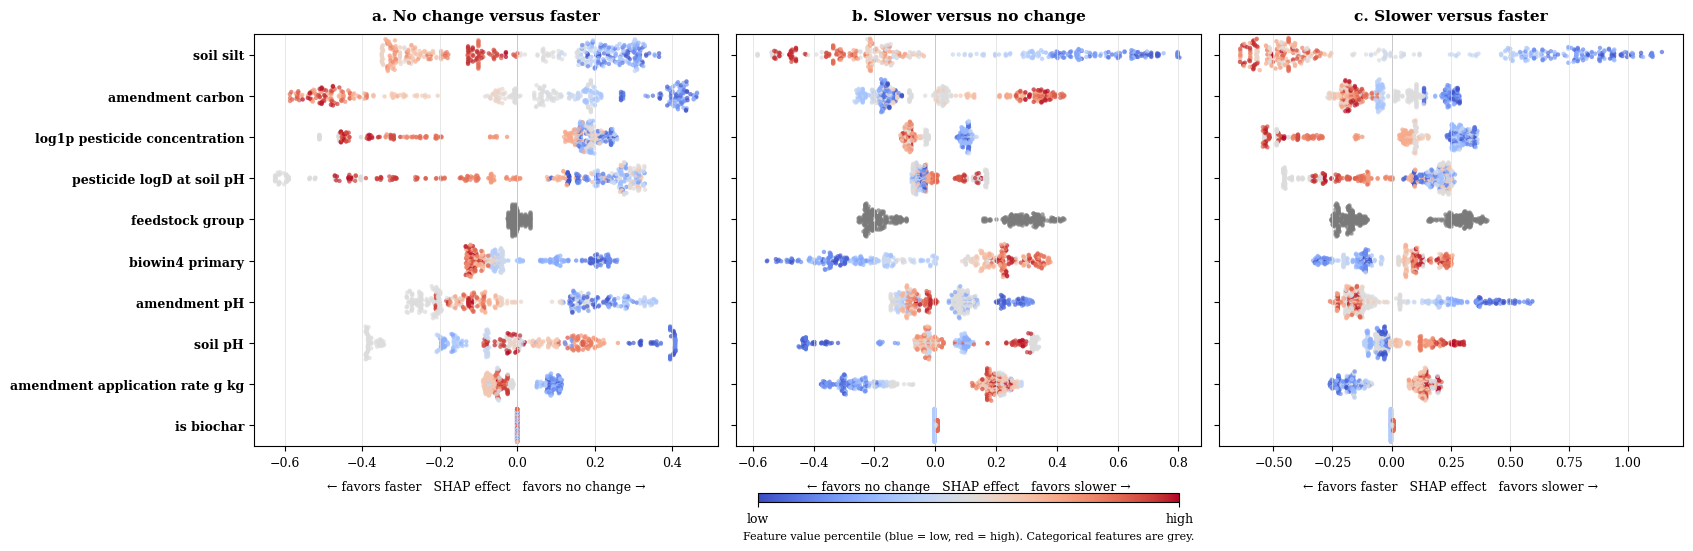

/tmp/ipykernel_3548/2937190247.py:88: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  axis.scatter(selected, y + offsets, c=colours, cmap=COLOURMAP, vmin=0, vmax=1,


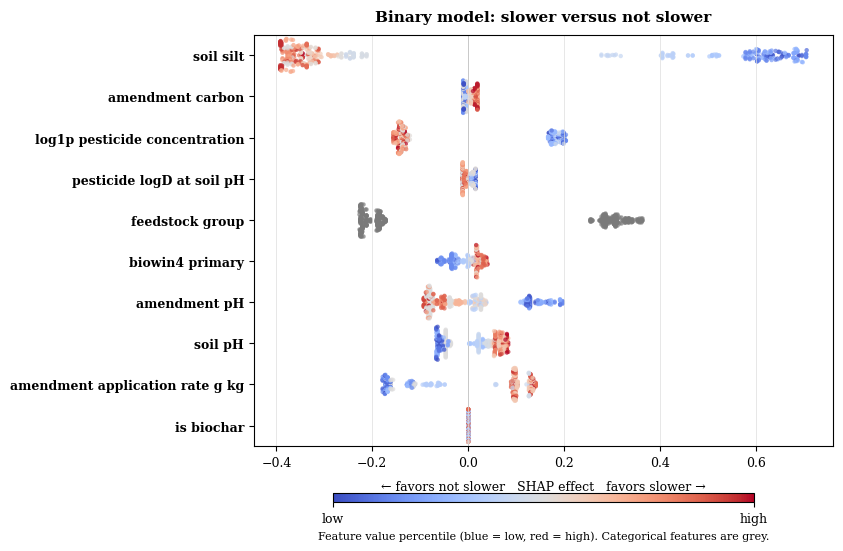

In [28]:
# --- execution cell ---
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

CATEGORICAL_GREY = "#7a7a7a"
COLOURMAP = plt.get_cmap("coolwarm")

PLOT_TOP_N = 15
PLOT_EXPAND_LEVELS = False

order = ranking.sort_values("model_a", ascending=False).index.tolist()[:PLOT_TOP_N]
def build_rows(feature_order, X, categorical, expand_levels):
    """Build rows for SHAP beeswarm visualization."""
    rows = []
    for feature in feature_order:
        if feature not in X.columns:
            continue
        
        column = X[feature]
        is_categorical = feature in categorical
        
        if is_categorical and expand_levels:
            # One row per category level
            for level in column.cat.categories:
                rows.append({
                    "feature": feature,
                    "label": f"{feature}\n{level}",
                    "header": False,
                    "is_categorical": True,
                    "level": level,
                })
        else:
            # Single row per feature
            rows.append({
                "feature": feature,
                "label": feature,
                "header": True,
                "is_categorical": is_categorical,
                "level": None,
            })
    
    return rows


def beeswarm_offsets(values, step=0.12, bins=40, spread=0.40):
    """Return deterministic vertical offsets for points with similar x values."""
    values = np.asarray(values, dtype=float)
    offsets = np.zeros(len(values), dtype=float)
    finite = np.isfinite(values)
    if finite.sum() < 2:
        return offsets
    lo, hi = np.nanmin(values[finite]), np.nanmax(values[finite])
    if np.isclose(lo, hi):
        groups = np.zeros(finite.sum(), dtype=int)
    else:
        groups = np.clip(((values[finite] - lo) / (hi - lo) * bins).astype(int), 0, bins - 1)
    finite_indices = np.flatnonzero(finite)
    for group in np.unique(groups):
        indices = finite_indices[groups == group]
        pattern = np.ravel(np.column_stack((np.arange(len(indices)), -np.arange(len(indices)))))[1:len(indices)+1]
        offsets[indices] = pattern * step

    # --- keep the swarm inside its own row ---
    peak = np.abs(offsets).max()
    if peak > spread:
        offsets = offsets * (spread / peak)
    return offsets


def draw_panel(axis, rows, panel_values, X, feature_index, title, subtitle):
    """Draw one SHAP beeswarm panel using the expanded row specification."""
    for y, row in enumerate(rows):
        feature = row["feature"]
        values = np.asarray(panel_values[:, feature_index[feature]], dtype=float)
        raw = X[feature]
        mask = np.isfinite(values)
        if row["level"] is not None:
            mask &= raw.astype(object).eq(row["level"]).to_numpy()
        selected = values[mask]
        if not len(selected):
            continue
        offsets = beeswarm_offsets(selected)
        if row["is_categorical"]:
            colours = CATEGORICAL_GREY
        else:
            numeric = pd.to_numeric(raw, errors="coerce").to_numpy(dtype=float)[mask]
            colours = pd.Series(numeric).rank(pct=True).fillna(0.5).to_numpy()
        axis.scatter(selected, y + offsets, c=colours, cmap=COLOURMAP, vmin=0, vmax=1,
                     s=10, alpha=0.7, linewidths=0, rasterized=True)
    axis.axvline(0, color="#999999", linewidth=0.7, zorder=0)
    axis.set_yticks(np.arange(len(rows)))
    axis.set_ylim(len(rows) - 0.5, -0.5)
    axis.set_xlabel(subtitle, fontsize=9, labelpad=8)
    axis.set_title(title, fontsize=11, fontweight="bold", pad=10)
    axis.grid(axis="x", color="#dddddd", linewidth=0.5)


rows = build_rows(order, X, categorical, PLOT_EXPAND_LEVELS)
feature_index = {name: i for i, name in enumerate(features)}
height = max(6.0, 0.42 * len(rows) + 1.5)

COLOURBAR_LABEL = ("Feature value percentile (blue = low, red = high). "
                   "Categorical features are grey.")


def add_colourbar(figure, axes):
    bar = figure.colorbar(
        ScalarMappable(norm=Normalize(0, 1), cmap=COLOURMAP),
        ax=axes, orientation="horizontal", fraction=0.02, pad=0.10, aspect=45,
    )
    bar.set_ticks([0, 1])
    bar.set_ticklabels(["low", "high"])
    bar.set_label(COLOURBAR_LABEL, fontsize=8)


def label_axis(axis, rows):
    labels = [row["label"].replace("_", " ") for row in rows]
    axis.set_yticklabels(labels, fontsize=9)
    for row, label in zip(rows, axis.get_yticklabels()):
        if row["header"]:
            label.set_fontweight("bold")


# Figure 1 -- Model A, the three pairwise contrasts.
figure_a, axes_a = plt.subplots(1, 3, figsize=(17, height), sharey=True)
for axis, (panel_values, title, subtitle) in zip(axes_a, PANELS_A):
    draw_panel(axis, rows, panel_values, X, feature_index, title, subtitle)
label_axis(axes_a[0], rows)
figure_a.tight_layout(rect=(0, 0.055, 1, 1))
add_colourbar(figure_a, axes_a)
figure_a.savefig(OUTPUT_ROOT / "shap_panels_three_class.png", dpi=250, bbox_inches="tight")
figure_a.savefig(OUTPUT_ROOT / "shap_panels_three_class.pdf", bbox_inches="tight")
plt.show()

# Figure 2 -- Model B, its own logit, same row order so the eye can carry across.
figure_b, axis_b = plt.subplots(1, 1, figsize=(8.5, height))
panel_values, title, subtitle = PANELS_B[0]
draw_panel(axis_b, rows, panel_values, X, feature_index, title, subtitle)
label_axis(axis_b, rows)
figure_b.tight_layout(rect=(0, 0.055, 1, 1))
add_colourbar(figure_b, [axis_b])
figure_b.savefig(OUTPUT_ROOT / "shap_panels_binary.png", dpi=250, bbox_inches="tight")
figure_b.savefig(OUTPUT_ROOT / "shap_panels_binary.pdf", bbox_inches="tight")
plt.show()

## 11. Ordinal Version of the Model 
Here we have the outputs ranked from slower --> no change --> faster. This is a new way of looking at it and it works by calculating a score and then seeing in which bucket it falls. Having to move all the way accross from slower-faster is much harder now. 

Interpretation of the SHAP values: 

SHAP values are per-row contributions to the model's output, measured against an average
row. For the ordinal model that output is a single score, so there is one value per feature
per row and one panel, rather than the three pairwise contrasts section 10.2 required. The
three-class model has three scores identified only up to a common shift, which is why
contrasts were needed there and are not needed here.

Values are in units of the score, which runs from 0 at faster to 2 at slower. A value of
+0.4 means the feature moved that row four tenths of a class step toward slower. Per row
the values sum to the score minus its mean, as asserted in the SHAP cell.

The shaded band is the no-change window. It is not at 0.5 and 1.5: squared-error regression
fits a conditional mean, and the fitted scores here have roughly half the spread of the
targets, so midpoint cuts would classify most rows as no change. The cuts are set at the
training-fold score quantiles matching the training class proportions, at approximately
[FILL: model_c.cuts]. They are refitted per fold, so their variation across folds is in
`folds_c[["cut1", "cut2"]]`, and the near-correct class balance in the predictions follows
from their placement rather than from model performance.

In the upper panel the cuts are decision boundaries. In the beeswarm they are not: a point
is one feature's contribution, not a row's total, so position relative to the band does not
determine the predicted class. The band serves as a scale reference. A swarm wider than the
band indicates a feature able to move a row across a class boundary on its own; a swarm
much narrower indicates one that cannot.

The ordinal model has one direction and cannot represent a feature acting on no change
against both extremes. The `off_axis` column in section 10.2's ranking measures how much of
each feature's influence in the three-class model was of that kind, and `r_with_lin_a` in
`ranking_c` shows how much of it carried over. A feature that appears weak here and scores
poorly on both should be attributed to the restriction, not read as unimportant.

Widths are not comparable with the three-class or binary panels, which are in log-odds.
Rankings are.

In [29]:
# --- execution cell: Model C, ordinal ---
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score
from xgboost import XGBRegressor

CUTS = (0.5, 1.5)          # midpoints between the 0/1/2 targets; the default, not what is used
ORDINAL_VARIANT = "ordinal"

# `balanced` weighting centres the fitted score on 1.0, the middle of the no-change band,
# which is the worst place for it. Pinned off for this model.
ORDINAL_SEARCH_SPACE = {**SEARCH_SPACE, "class_weight": [None]}


class OrdinalXGB:
    """A regressor on 0/1/2, wearing the same interface as `LabelledXGB`.

    `decision_function` is the single latent score; `predict` cuts it at `self.cuts`. No
    `predict_proba`: the model does not produce one, and nothing downstream asks for it.
    """

    def __init__(self, model: XGBRegressor, classes: list[str], cuts=CUTS):
        self.model = model
        self.classes_ = np.asarray(classes, dtype=object)
        self.cuts = np.asarray(cuts, dtype=float)

    def decision_function(self, X):
        return np.asarray(self.model.predict(X), dtype=float)

    def predict(self, X):
        return self.classes_[np.digitize(self.decision_function(X), self.cuts)]


def fit_ordinal(params, X, y, seed, categorical=None):
    """Same call signature as `fit_model`.

    `reg:squarederror` fits a conditional mean, so the predictions are shrunk toward the
    marginal mean and pile up between the midpoint cuts. The cuts are therefore placed at
    the training-fold quantiles matching the training class proportions instead. They are
    derived from training rows only and nothing about them is searched.
    """
    settings = dict(params)
    weighting = settings.pop("class_weight", None)

    codes = pd.Categorical(y, categories=ORDER).codes
    if (codes < 0).any():
        raise ValueError("target contains labels outside the expected set")

    weights = compute_sample_weight("balanced", codes) if weighting == "balanced" else None

    model = XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        enable_categorical=True,
        max_cat_to_onehot=MAX_CAT_TO_ONEHOT,
        random_state=seed,
        n_jobs=1,
        monotone_constraints = monotone_constraints(X),
        **settings,
    )
    model.fit(X, codes.astype(float), sample_weight=weights)

    raw = np.asarray(model.predict(X), dtype=float)
    quantiles = np.cumsum(np.bincount(codes, minlength=3)[:2]) / len(codes)
    return OrdinalXGB(model, ORDER, np.quantile(raw, quantiles))


def score_draw_ordinal(params, X, y, splits, seed, categorical):
    return np.mean([
        balanced_accuracy_score(
            y.iloc[validation],
            fit_ordinal(params, X.iloc[training], y.iloc[training], seed, categorical).predict(
                X.iloc[validation]
            ),
        )
        for training, validation in splits
    ])


def inner_search_ordinal(X, y, groups, seed, categorical):
    """Identical in form to `inner_search`, so the two models are selected the same way."""
    splitter = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=seed)
    splits = list(splitter.split(X, y, groups))
    draws = list(ParameterSampler(ORDINAL_SEARCH_SPACE, n_iter=N_DRAWS, random_state=seed))
    scores = Parallel(n_jobs=-1)(
        delayed(score_draw_ordinal)(params, X, y, splits, seed, categorical) for params in draws
    )
    best = int(np.argmax(scores))
    return draws[best], float(scores[best])


def run_one_ordinal(frame, features, seed, categorical, variant=ORDINAL_VARIANT,
                    keep_models=True):
    """Model C. Stratifies on `response_class`, so at a given seed the folds are Model A's."""
    X = frame[features]
    observed = frame["response_class"]
    groups = frame["Study ID"]
    outer = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)

    predicted = pd.Series(pd.NA, index=frame.index, dtype="object")
    score = pd.Series(np.nan, index=frame.index)
    fold_ids = pd.Series(np.nan, index=frame.index)
    fold_rows, fits = [], []

    for fold, (training, test) in enumerate(outer.split(X, observed, groups)):
        params, inner = inner_search_ordinal(
            X.iloc[training], observed.iloc[training], groups.iloc[training], seed, categorical
        )
        model = fit_ordinal(params, X.iloc[training], observed.iloc[training], seed, categorical)

        score.iloc[test] = model.decision_function(X.iloc[test])
        predicted.iloc[test] = model.predict(X.iloc[test])
        fold_ids.iloc[test] = fold

        fold_rows.append({
            "variant": variant, "seed": seed, "fold": fold,
            "n_test": len(test), "studies_test": groups.iloc[test].nunique(),
            "inner_bacc": inner,
            "outer_bacc": balanced_accuracy_score(observed.iloc[test], predicted.iloc[test]),
            "score_mean": float(score.iloc[test].mean()),
            "score_sd": float(score.iloc[test].std()),
            "cut1": float(model.cuts[0]), "cut2": float(model.cuts[1]),
            **{f"hp_{name}": value for name, value in params.items()},
        })
        if keep_models:
            fits.append({"variant": variant, "seed": seed, "fold": fold,
                         "training": training, "test": test, "model": model})

    obs_code = pd.Categorical(observed, categories=ORDER).codes
    pred_code = pd.Categorical(predicted, categories=ORDER).codes
    recalls = recall_score(observed, predicted, labels=ORDER, average=None)
    reversals = reversal_mask(observed, predicted)
    metrics = {
        "variant": variant, "seed": seed,
        "bal_acc": balanced_accuracy_score(observed, predicted),
        "accuracy": accuracy_score(observed, predicted),
        "macro_f1": f1_score(observed, predicted, average="macro"),
        **{f"recall_{label.replace(' ', '_')}": value for label, value in zip(ORDER, recalls)},
        "reversal_rate": float(reversals.mean()),
        "n_reversals": int(reversals.sum()),
        # Ordinal-specific: distance in class steps, agreement penalised by squared distance,
        # and rank agreement on the latent score, which is free of the cuts.
        "mae_steps": float(np.abs(pred_code - obs_code).mean()),
        "qwk": float(cohen_kappa_score(obs_code, pred_code, weights="quadratic")),
        "spearman_score": float(spearmanr(score, obs_code).statistic),
    }
    oof = _oof_frame(frame, groups, {
        "variant": variant, "seed": seed, "fold": fold_ids,
        "observed": observed, "predicted": predicted,
        "correct": observed.eq(predicted),
        "directional_reversal": reversals,
        "score": score,
    })
    return metrics, oof, pd.DataFrame(fold_rows), fits


started = time.time()
metrics_c, oof_c, folds_c, fits_c = run_variant(
    frame, features, categorical, run_one_ordinal, ORDINAL_VARIANT,
)
print(f"elapsed: {(time.time() - started) / 60:.1f} min")
display(metrics_c.drop(columns="variant").round(4))
display(metrics_c.drop(columns=["variant", "seed"]).agg(["mean", "std"]).round(4))

# Shrinkage and cut stability. Score sd well under the target sd means the fitted scale is
# compressed; cuts scattering across folds means the refit model's cuts are not typical.
print("\ntarget sd:", round(float(pd.Categorical(frame['response_class'],
                                                 categories=ORDER).codes.std()), 3))
display(folds_c[["score_mean", "score_sd", "cut1", "cut2"]].describe().round(3))

# Refit over all rows, exactly as section 9 does for A and B.
searched_c = [inner_search_ordinal(X, y_three, groups, seed, categorical) for seed in SEEDS]
best_c = max(range(len(searched_c)), key=lambda i: searched_c[i][1])
model_c = fit_ordinal(searched_c[best_c][0], X, y_three, SEEDS[best_c], categorical)
print(f"\nModel C: seed {SEEDS[best_c]}, inner bacc {searched_c[best_c][1]:.3f}, "
      f"cuts {np.round(model_c.cuts, 3)}")

# Paired against Model A on the same folds. Only valid because both stratify on the same label.
paired = oof_a[["seed", "observed", "predicted"]].rename(columns={"predicted": "pred_a"})
paired["pred_c"] = oof_c["predicted"].to_numpy()
fixed = reversal_mask(paired["observed"], paired["pred_a"]) & ~reversal_mask(
    paired["observed"], paired["pred_c"])
introduced = ~reversal_mask(paired["observed"], paired["pred_a"]) & reversal_mask(
    paired["observed"], paired["pred_c"])
print(f"reversals fixed by C: {fixed.sum():,}   introduced by C: {introduced.sum():,}   "
      f"of {len(paired):,} pooled rows")

ordinal          seed 0: bacc=0.485 acc=0.496 F1=0.483 rev=0.144
ordinal          seed 1: bacc=0.495 acc=0.507 F1=0.493 rev=0.120
ordinal          seed 2: bacc=0.460 acc=0.467 F1=0.458 rev=0.127
ordinal          seed 3: bacc=0.479 acc=0.478 F1=0.474 rev=0.109
ordinal          seed 4: bacc=0.532 acc=0.564 F1=0.532 rev=0.140
elapsed: 0.6 min


,seed,bal_acc,accuracy,macro_f1,recall_faster,recall_no_change,recall_slower,reversal_rate,n_reversals,mae_steps,qwk,spearman_score
0,0,0.4853,0.4956,0.4831,0.5202,0.4151,0.5205,0.1444,65,0.6489,0.3447,0.3079
1,1,0.4947,0.5067,0.4928,0.5657,0.4528,0.4658,0.1200,54,0.6133,0.3900,0.4182
2,2,0.4603,0.4667,0.4581,0.4949,0.4340,0.4521,0.1267,57,0.6600,0.3422,0.4062
3,3,0.4785,0.4778,0.4736,0.4596,0.4623,0.5137,0.1089,49,0.6311,0.3826,0.4092
4,4,0.5320,0.5644,0.5320,0.6717,0.3491,0.5753,0.1400,63,0.5756,0.4341,0.4218


,bal_acc,accuracy,macro_f1,recall_faster,recall_no_change,recall_slower,reversal_rate,n_reversals,mae_steps,qwk,spearman_score
mean,0.4902,0.5022,0.4879,0.5424,0.4226,0.5055,0.1280,57.6000,0.6258,0.3787,0.3926
std,0.0266,0.0381,0.0278,0.0820,0.0449,0.0490,0.0145,6.5422,0.0332,0.0377,0.0478



target sd: 0.867


,score_mean,score_sd,cut1,cut2
count,25.000,25.000,25.000,25.000
mean,0.951,0.342,0.756,1.153
std,0.118,0.092,0.055,0.082
min,0.783,0.179,0.628,1.024
25%,0.853,0.276,0.725,1.105
50%,0.931,0.333,0.767,1.138
75%,1.046,0.414,0.787,1.184
max,1.210,0.513,0.837,1.400



Model C: seed 4, inner bacc 0.549, cuts [0.748 1.19 ]
reversals fixed by C: 191   introduced by C: 57   of 2,250 pooled rows


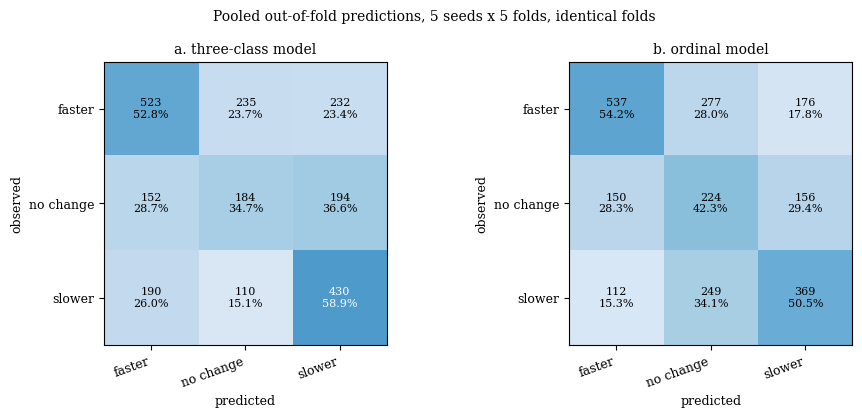

,faster,no change,slower
faster,537,277,176
no change,150,224,156
slower,112,249,369


,faster,no change,slower
faster,0.014,0.042,-0.057
no change,-0.004,0.075,-0.072
slower,-0.107,0.190,-0.084


three-class  reversals:  422 (18.8%)   predicted no change:  529
ordinal      reversals:  288 (12.8%)   predicted no change:  750


In [30]:
# --- execution cell ---
figure, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
counts_a3 = confusion_panel(axes[0], oof_a["observed"], oof_a["predicted"], ORDER,
                            "a. three-class model")
counts_c = confusion_panel(axes[1], oof_c["observed"], oof_c["predicted"], ORDER,
                           "b. ordinal model")
figure.suptitle("Pooled out-of-fold predictions, 5 seeds x 5 folds, identical folds",
                fontsize=10)
figure.tight_layout()
figure.savefig(OUTPUT_ROOT / "confusion_ordinal.png", dpi=200, bbox_inches="tight")
plt.show()

display(pd.DataFrame(counts_c, index=ORDER, columns=ORDER))

# Row-normalised difference. Positive means the ordinal model puts more mass in that cell.
shares = lambda c: c / c.sum(axis=1, keepdims=True)
display((pd.DataFrame(shares(counts_c) - shares(counts_a3), index=ORDER, columns=ORDER)
         .round(3)))

for name, oof in [("three-class", oof_a), ("ordinal", oof_c)]:
    print(f"{name:<12} reversals: {oof['directional_reversal'].sum():>4,} "
          f"({oof['directional_reversal'].mean():.1%})   "
          f"predicted no change: {oof['predicted'].eq('no change').sum():>4,}")

In [31]:
# --- execution cell ---
started = time.time()
values_c, base_c, residual_c = permutation_shap(model_c, X, X_codes)
print(f"elapsed: {(time.time() - started) / 60:.1f} min")

shap_ordinal = values_c[:, :, 0]
base_ordinal = float(np.atleast_1d(base_c)[0])
print(f"Model C: values {values_c.shape}, base {base_ordinal:.4f}, residual {residual_c:.3e}")
assert residual_c < 1e-4, "permutation values are not additive"

ranking_c = pd.DataFrame({
    "ordinal": np.abs(shap_ordinal).mean(axis=0),
    "model_a": ranking["model_a"],
    "off_axis": ranking["off_axis"],
}, index=features)
ranking_c["share"] = ranking_c["ordinal"] / ranking_c["ordinal"].sum()
# Does the ordinal score recover Model A's ordinal coordinate? Compared per row, per feature.
ranking_c["r_with_lin_a"] = [
    spearmanr(shap_ordinal[:, j], _lin[:, j]).statistic for j in range(len(features))
]
display(ranking_c.sort_values("ordinal", ascending=False).round(4))

PermutationExplainer explainer: 451it [00:48,  7.59it/s]                         

elapsed: 0.8 min
Model C: values (450, 10, 1), base 0.8124, residual 4.441e-16


,ordinal,model_a,off_axis,share,r_with_lin_a
soil_silt,0.2235,0.4109,0.0652,0.3136,0.8431
soil_pH,0.1328,0.1694,0.8233,0.1865,0.8076
amendment_pH,0.0717,0.1796,0.2601,0.1006,0.7967
log1p_pesticide_concentration,0.0655,0.2237,0.1539,0.0919,0.7939
feedstock_group,0.0623,0.1928,0.2699,0.0875,0.8301
biowin4_primary,0.0591,0.1820,0.6374,0.0829,0.8104
pesticide_logD_at_soil_pH,0.0451,0.2052,0.4732,0.0633,0.8159
amendment_application_rate_g_kg,0.0313,0.1637,0.5294,0.0439,0.7833
amendment_carbon,0.0167,0.2297,0.7759,0.0234,-0.2029
is_biochar,0.0046,0.0026,0.2500,0.0064,0.8028


/tmp/ipykernel_3548/2937190247.py:88: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  axis.scatter(selected, y + offsets, c=colours, cmap=COLOURMAP, vmin=0, vmax=1,
/tmp/ipykernel_3548/2073212998.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure_c.tight_layout(rect=(0, 0.055, 1, 1))


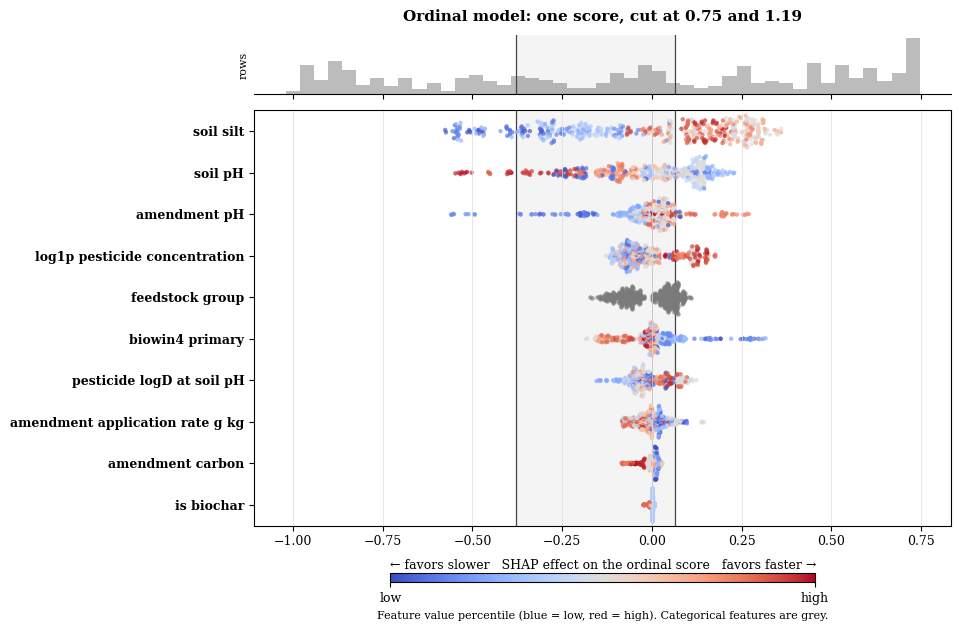

cuts [0.748 1.19 ], base 0.812, plotted window -0.378 to 0.065 (width 0.443); axis is the negated score


In [32]:
# --- execution cell ---
ORDINAL_ROW_ORDER = "own"      # "own" or "model_a" to keep section 10's row order

order_c = (ranking_c.sort_values("ordinal", ascending=False).index.tolist()[:PLOT_TOP_N]
           if ORDINAL_ROW_ORDER == "own" else order)
rows_c = build_rows(order_c, X, categorical, PLOT_EXPAND_LEVELS)
height_c = max(6.0, 0.42 * len(rows_c) + 1.5)

# Displayed axis is the negated score, so slower reads left and faster right. Ranking,
# additivity and `ranking_c` are all unaffected: this is a sign flip at draw time only.
window = tuple(sorted(base_ordinal - np.asarray(model_c.cuts, dtype=float)))
scores_all = base_ordinal - model_c.decision_function(X)
shap_plot = -shap_ordinal

figure_c, (axis_top, axis_c) = plt.subplots(
    2, 1, figsize=(9.0, height_c + 1.1), sharex=True,
    gridspec_kw={"height_ratios": [1, 8], "hspace": 0.06},
)

# Marginal panel. Here the cuts are decision boundaries.
axis_top.hist(scores_all, bins=45, color="#bcbcbc", edgecolor="none")
for edge in window:
    axis_top.axvline(edge, color="#444444", linewidth=0.9)
axis_top.axvspan(*window, color="#444444", alpha=0.06, linewidth=0)
axis_top.set_yticks([])
axis_top.set_ylabel("rows", fontsize=8)
axis_top.set_title(
    f"Ordinal model: one score, cut at {model_c.cuts[0]:.2f} and {model_c.cuts[1]:.2f}",
    fontsize=11, fontweight="bold", pad=10,
)
for side in ("top", "right", "left"):
    axis_top.spines[side].set_visible(False)

# Beeswarm. Same band, but a scale reference rather than a boundary.
draw_panel(axis_c, rows_c, shap_plot, X, feature_index, "",
           "← favors slower   SHAP effect on the ordinal score   favors faster →")
axis_c.axvspan(*window, color="#444444", alpha=0.06, linewidth=0, zorder=0)
for edge in window:
    axis_c.axvline(edge, color="#444444", linewidth=0.9, zorder=0)
label_axis(axis_c, rows_c)

figure_c.tight_layout(rect=(0, 0.055, 1, 1))
add_colourbar(figure_c, [axis_c])
figure_c.savefig(OUTPUT_ROOT / "shap_panel_ordinal.png", dpi=250, bbox_inches="tight")
figure_c.savefig(OUTPUT_ROOT / "shap_panel_ordinal.pdf", bbox_inches="tight")
plt.show()

print(f"cuts {np.round(model_c.cuts, 3)}, base {base_ordinal:.3f}, "
      f"plotted window {window[0]:.3f} to {window[1]:.3f} "
      f"(width {window[1] - window[0]:.3f}); axis is the negated score")

NOTE: the bands is the boundary for a row starting at the average score. notebook uses PermutationExplainer against a background sample of 100 rows. To find what a feature contributed for a given row, it takes that row, replaces the feature's value with the value drawn from a background row, and sees how the score moves. It does this across many orderings of the features, so the value it lands on accounts for the feature acting in combination with the others rather than in isolation. Shapley values do this in a game theory way according to the 4 axioms as defined by Shapley in the 1950s. The background row is supposed to be the true average, based on random sampling. 

## 12. Plot the Ordinal Scores vs the raw logDT50 values
This is what is bucketed by the ordinal model. Here we can see how close the regressions got. 

boundaries at [-0.2218  0.2147] ln units ([-19.9  23.9]% change), gaps [0.01855 0.02487]


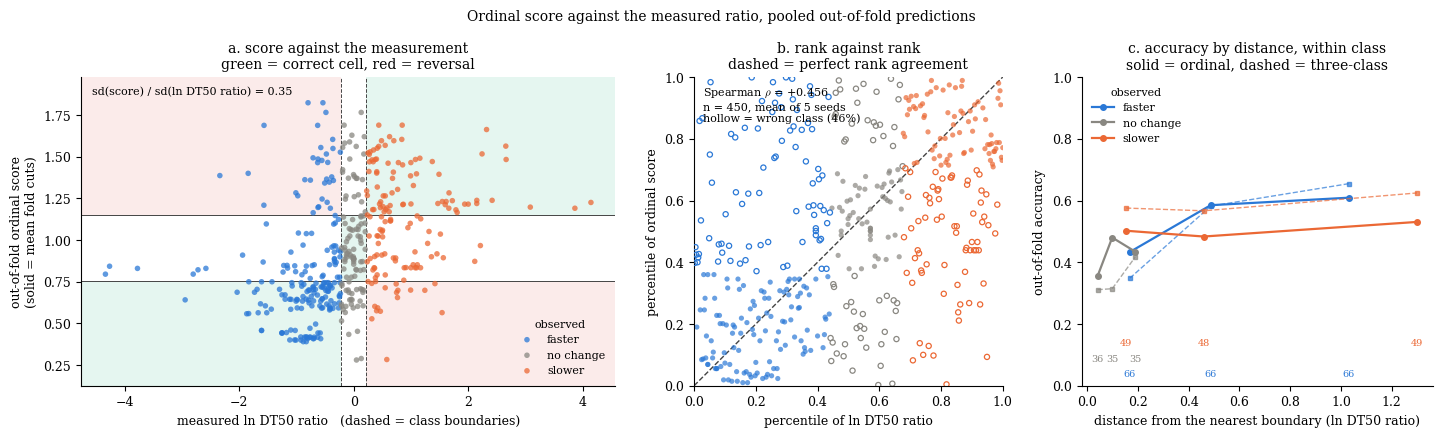

In [33]:
# --- execution cell: ordinal score against the measured ratio ---
#
# Not a replacement for section 11's beeswarm. That plot reads the cuts as decision
# boundaries in score space; these three put the score next to the quantity the classes were
# cut from. Panel a is the confusion matrix laid out over the measurement axis, so it shows
# where along the ratio the errors fall. Panel b rescales both axes to percentiles, the only
# version where a diagonal means anything. Panel c splits the distance effect by class,
# because distance from the cut is not independent of class -- every no-change row is inside
# the band by construction -- and pooled, a changing class mix reads as a distance effect.
from scipy.stats import spearmanr
from matplotlib.patches import Rectangle

RATIO_COLUMN = "ln_DT50_ratio"
N_DISTANCE_BINS = 3          # per class, so ~60 rows a point rather than ~30
AXIS_LABEL = "ln DT50 ratio"

x_all = frame[RATIO_COLUMN].astype(float)
observed_all = frame["response_class"]
code_all = pd.Categorical(observed_all, categories=ORDER).codes

# ---------------------------------------------------------------- boundaries from the labels
# response_class is a hard cut on this column, so each class occupies one interval and the
# boundary sits between the top of one and the bottom of the next.
cuts_x, gaps = [], []
for lower, upper in zip(ORDER[:-1], ORDER[1:]):
    top = x_all[observed_all.eq(lower)].max()
    bottom = x_all[observed_all.eq(upper)].min()
    cuts_x.append((top + bottom) / 2)
    gaps.append(bottom - top)
cuts_x = np.asarray(cuts_x, dtype=float)
if min(gaps) <= 0:
    raise ValueError(f"class intervals overlap; response_class is not a hard cut on {RATIO_COLUMN}")
print(f"boundaries at {np.round(cuts_x, 4)} ln units "
      f"({np.round(100 * (np.exp(cuts_x) - 1), 1)}% change), gaps {np.round(gaps, 5)}")

# ---------------------------------------------------------------- align oof rows to frame rows
if not frame["analysis_row_id"].is_unique:
    raise ValueError("analysis_row_id is not unique; cannot align oof rows to frame rows")
position = pd.Series(np.arange(len(frame)), index=frame["analysis_row_id"])


def row_position(oof, name):
    """Frame row index for every oof row, checked against the observed label."""
    key = oof["analysis_row_id"].map(position)
    if key.isna().any():
        raise ValueError(f"{name} carries ids that are not in the frame")
    key = key.to_numpy()
    if not (oof["observed"].to_numpy() == observed_all.to_numpy()[key]).all():
        raise ValueError(f"{name}: observed labels disagree with the frame after the id join")
    return key


key_c = row_position(oof_c, "oof_c")
n_reps = len(oof_c) // len(frame)

per_row = (
    pd.DataFrame({"row": key_c, "score": oof_c["score"].to_numpy(),
                  "correct": oof_c["correct"].to_numpy()})
    .groupby("row")
    .agg(score=("score", "mean"), acc_c=("correct", "mean"))
    .reindex(np.arange(len(frame)))
)
per_row["x"] = x_all.to_numpy()
per_row["observed"] = observed_all.to_numpy()
per_row["distance"] = np.abs(per_row["x"].to_numpy()[:, None] - cuts_x[None, :]).min(axis=1)

# Model A on the same rows. A and C stratify on the same label, so at a given seed the folds
# match; if that ever stops being true the comparison drops out rather than misleading.
try:
    key_a = row_position(oof_a, "oof_a")
    per_row["acc_a"] = (pd.Series(oof_a["correct"].to_numpy()).groupby(key_a).mean()
                        .reindex(np.arange(len(frame))).to_numpy())
except (KeyError, ValueError) as problem:
    print(f"three-class comparison in panel c skipped: {problem}")
    per_row["acc_a"] = np.nan

panel = per_row.dropna(subset=["x", "score"]).copy()
panel["rank_x"] = panel["x"].rank(pct=True)
panel["rank_score"] = panel["score"].rank(pct=True)

# ---------------------------------------------------------------- figure
CLASS_COLOUR = {"faster": "#2a78d6", "no change": "#898781", "slower": "#eb6834"}
CORRECT_FILL, REVERSAL_FILL = "#1baf7a", "#e34948"
cuts_y = folds_c[["cut1", "cut2"]].mean().to_numpy()

figure, (ax, ax_r, ax_d) = plt.subplots(
    1, 3, figsize=(14.5, 4.4), gridspec_kw={"width_ratios": [1.9, 1.15, 1.25]}
)

# a. the nine cells the two sets of cuts define. Diagonal is correct, far corners are the
#    reversals metrics_c counts, unshaded cells are one-step errors.
pad_x = 0.05 * np.ptp(panel["x"])
pad_y = 0.10 * np.ptp(panel["score"])
xlim = (panel["x"].min() - pad_x, panel["x"].max() + pad_x)
ylim = (panel["score"].min() - pad_y, panel["score"].max() + pad_y)
x_edges = np.concatenate([[xlim[0]], cuts_x, [xlim[1]]])
y_edges = np.concatenate([[ylim[0]], np.sort(cuts_y), [ylim[1]]])

for i in range(3):
    for j in range(3):
        fill = (CORRECT_FILL if i == j else REVERSAL_FILL if abs(i - j) == 2 else None)
        if fill is None:
            continue
        ax.add_patch(Rectangle(
            (x_edges[i], y_edges[j]), x_edges[i + 1] - x_edges[i], y_edges[j + 1] - y_edges[j],
            facecolor=fill, alpha=0.11, edgecolor="none", zorder=0))

for label in ORDER:
    part = panel[panel["observed"].eq(label)]
    ax.scatter(part["x"], part["score"], s=16, alpha=0.75, zorder=3,
               color=CLASS_COLOUR[label], edgecolor="none", label=label)
for edge in cuts_x:
    ax.axvline(edge, color="#444444", linewidth=0.7, linestyle="--", zorder=2)
for edge in cuts_y:
    ax.axhline(edge, color="#444444", linewidth=0.7, zorder=2)

ax.set_xlim(*xlim)
ax.set_ylim(*ylim)
ax.set_xlabel(f"measured {AXIS_LABEL}   (dashed = class boundaries)")
ax.set_ylabel("out-of-fold ordinal score\n(solid = mean fold cuts)")
ax.set_title("a. score against the measurement\ngreen = correct cell, red = reversal", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right", title="observed", title_fontsize=8)
ax.annotate(f"sd(score) / sd({AXIS_LABEL}) = {panel['score'].std() / panel['x'].std():.2f}",
            xy=(0.02, 0.97), xycoords="axes fraction", va="top", fontsize=8)

# b. both axes on percentiles, the only scaling where the identity line is a claim.
#    Correctness is adjudicated as in panel a: mean score against the same cuts.
predicted_mean = np.asarray(ORDER, dtype=object)[
    np.digitize(panel["score"].to_numpy(), np.sort(cuts_y))
]
panel["missed"] = predicted_mean != panel["observed"].to_numpy()

ax_r.plot([0, 1], [0, 1], color="#444444", linewidth=1.0, linestyle="--", zorder=1)
for label in ORDER:
    part = panel[panel["observed"].eq(label)]
    right, wrong = part[~part["missed"]], part[part["missed"]]
    ax_r.scatter(right["rank_x"], right["rank_score"], s=14, alpha=0.7, zorder=2,
                 color=CLASS_COLOUR[label], edgecolor="none")
    ax_r.scatter(wrong["rank_x"], wrong["rank_score"], s=14, zorder=3, facecolor="none",
                 edgecolor=CLASS_COLOUR[label], linewidth=0.9)

rho = spearmanr(panel["x"], panel["score"]).statistic
ax_r.annotate(f"Spearman $\\rho$ = {rho:+.3f}\n"
              f"n = {len(panel):,}, mean of {n_reps} seeds\n"
              f"hollow = wrong class ({panel['missed'].mean():.0%})",
              xy=(0.03, 0.97), xycoords="axes fraction", va="top", fontsize=8)
ax_r.set_xlim(0, 1)
ax_r.set_ylim(0, 1)
ax_r.set_aspect("equal")
ax_r.set_xlabel(f"percentile of {AXIS_LABEL}")
ax_r.set_ylabel("percentile of ordinal score")
ax_r.set_title("b. rank against rank\ndashed = perfect rank agreement", fontsize=10)

# c. equal-count distance bins within each class. Counts are printed under each point.
for position_index, label in enumerate(ORDER):
    part = panel[panel["observed"].eq(label)]
    if len(part) < 2 * N_DISTANCE_BINS:
        continue
    bins = pd.qcut(part["distance"], q=N_DISTANCE_BINS, duplicates="drop")
    grouped = part.groupby(bins, observed=True).agg(
        centre=("distance", "median"), n=("distance", "size"),
        ordinal=("acc_c", "mean"), three_class=("acc_a", "mean"))
    ax_d.plot(grouped["centre"], grouped["ordinal"], marker="o", markersize=4,
              color=CLASS_COLOUR[label], linewidth=1.6, label=label)
    if grouped["three_class"].notna().all():
        ax_d.plot(grouped["centre"], grouped["three_class"], marker="s", markersize=3,
                  color=CLASS_COLOUR[label], linewidth=1.0, linestyle="--", alpha=0.7)
    for centre, count in zip(grouped["centre"], grouped["n"]):
        ax_d.annotate(f"{count}", xy=(centre, 0.03 + 0.05 * position_index), ha="center",
                      fontsize=7, color=CLASS_COLOUR[label])

ax_d.set_ylim(0, 1)
ax_d.set_xlabel(f"distance from the nearest boundary ({AXIS_LABEL})")
ax_d.set_ylabel("out-of-fold accuracy")
ax_d.set_title("c. accuracy by distance, within class\nsolid = ordinal, dashed = three-class",
               fontsize=10)
ax_d.legend(frameon=False, fontsize=8, loc="upper left", title="observed", title_fontsize=8)

for axis in (ax, ax_r, ax_d):
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)

figure.suptitle("Ordinal score against the measured ratio, pooled out-of-fold predictions",
                fontsize=10)
figure.tight_layout()
figure.savefig(OUTPUT_ROOT / "ordinal_score_vs_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

## Save


In [34]:
# --- execution cell ---
metrics_a.to_csv(OUTPUT_ROOT / "metrics_three_class.csv", index=False)
metrics_b.to_csv(OUTPUT_ROOT / "metrics_slower_or_not.csv", index=False)
oof_a.to_csv(OUTPUT_ROOT / "oof_three_class.csv", index=False)
oof_b.to_csv(OUTPUT_ROOT / "oof_slower_or_not.csv", index=False)
folds_a.to_csv(OUTPUT_ROOT / "folds_three_class.csv", index=False)
folds_b.to_csv(OUTPUT_ROOT / "folds_slower_or_not.csv", index=False)
ranking.to_csv(OUTPUT_ROOT / "shap_ranking.csv")

(OUTPUT_ROOT / "run_config.json").write_text(json.dumps({
    "baseline_run": str(BASELINE_RUN),
    "estimator": "xgboost.XGBClassifier",
    "xgboost_version": xgboost.__version__,
    "tree_method": "hist",
    "enable_categorical": True,
    "max_cat_to_onehot": MAX_CAT_TO_ONEHOT,
    "features": features,
    "categorical": categorical,
    "interactions": {name: list(parents) for name, parents in INTERACTIONS.items()},
    "matches_consensus_8": set(features) == set(CONSENSUS_8),
    "dropped": DROP,
    "seeds": SEEDS,
    "n_outer": N_OUTER, "n_inner": N_INNER, "n_draws": N_DRAWS,
    "search_mode": SEARCH_MODE,
    "model_b_cutoff": cutoff_b,
    "shap_residual_a": residual_a,
    "shap_residual_b": residual_b,
    "monotone": {name: int(sign) for name, sign in MONOTONE.items()},
}, indent=2))

with (OUTPUT_ROOT / "refit_models.pkl").open("wb") as handle:
    pickle.dump({"model_a": model_a, "model_b": model_b, "cutoff_b": cutoff_b,
                 "features": features, "categorical": categorical}, handle)

print("written to", OUTPUT_ROOT.resolve())


written to /home/jber/Soil_AI/work_20260820_Joris/Joris ML/RUN THIS MARIJA/outputs
